<a href="https://colab.research.google.com/github/wadmd27-dotcom/mangrove-dashboard/blob/main/mangrove_degradation_poc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌿 Ecosystem Health, Biodiversity & Blue Carbon
## Arab Youth Space Hackathon: 813 Challenge — Planet Tanager Hyperspectral Explorer

This notebook explores **Planet's Tanager hyperspectral satellite** for mapping **ecosystem health, biodiversity proxies, and blue carbon habitats** such as mangroves, seagrass beds, and coastal wetlands.

---

## What You Will Learn

- How hyperspectral data reveals biodiversity-related spectral traits
- How to compute indices linked to ecosystem function
- How to detect blue carbon habitats (mangroves, seagrass)
- How to identify potential harmful algal blooms (HABs)

---

## Why Blue Carbon?

**Blue carbon** refers to carbon stored in coastal ecosystems — mangroves, seagrass meadows, and salt marshes. These ecosystems:
- Store up to **5× more carbon per hectare** than tropical forests
- Protect coastlines from storm surge
- Provide nursery habitat for fish

Tanager's hyperspectral capability allows us to:
- Distinguish mangroves from other coastal vegetation using their unique spectral signature
- Detect chlorophyll in shallow water (seagrass, phytoplankton)
- Monitor ecosystem stress before visible degradation

---

## Relevant STAC Collection

```
https://www.planet.com/data/stac/tanager-core-imagery/coastal-water-bodies/collection.json
```


### 👋 First time here?

If this is your first notebook in the repo, we recommend starting with `00_EO_data_quickstart_notebook.ipynb` first. It walks through environment setup, key concepts (STAC, COGs, bands, hyperspectral vs. multispectral), and includes a troubleshooting guide that applies to all the notebooks here.

That said, this notebook is self-contained — the `%pip install` cell below installs everything it needs, so it will still run fine on its own (e.g. directly in Google Colab).

---

In [ ]:
%pip install pystac-client planetary-computer stackstac rasterio xarray matplotlib geopandas leafmap ipywidgets rioxarray h5py requests

You should consider upgrading via the '/Users/vincentmarkiet/Library/CloudStorage/OneDrive-Space42/dev/813_hackathon_/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
# Reset leafmap titiler endpoint to the public instance.
# This prevents errors if Planetary Computer cells ran earlier in the session.
os.environ["TITILER_ENDPOINT"] = "https://titiler.xyz"

## Step 1 – Load Items from the Coastal Water Bodies Collection

We target scenes near the UAE and Arabian Gulf — one of the most ecologically important mangrove coasts in the Arabian Peninsula.


In [ ]:
import requests

COLLECTION = "coastal-water-bodies"
item_ids = ["20250223_165546_32_4001","20250511_074311_00_4001", "20250223_165546_32_4001", "20250406_170447_47_4001"]

base = f"https://www.planet.com/data/stac/tanager-core-imagery/{COLLECTION}"
items = []
for iid in item_ids:
    url = f"{base}/{iid}/{iid}.json"
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    items.append(r.json())
print(f"Loaded {len(items)} items from {COLLECTION}")

item = items[0]   # work with the first scene

Loaded 4 items from coastal-water-bodies


## Step 2 – Inspect Scene Metadata


In [ ]:
from IPython.display import Image
print("Scene ID:", item["id"])
print("Date    :", item["properties"]["datetime"])
print("Bbox    :", item["bbox"])
Image(url=item["assets"]["thumbnail"]["href"])

Scene ID: 20250223_165546_32_4001
Date    : 2025-02-23T16:55:46.321891Z
Bbox    : [-88.56425877863482, 13.139414553891845, -88.34746243694369, 13.316052417927148]


In [ ]:
import json
print(json.dumps(item["properties"], indent=2))

{
  "cloud_percent": 0,
  "collection_mode": "standard_sensitivity",
  "constellation": "Tanager",
  "datetime": "2025-02-23T16:55:46.321891Z",
  "description": "All data products from Tanager-1 for 20250223_165546_32_4001 near Usulut\u00e1n, 3401, El Salvador",
  "gsd": 32.85,
  "instruments": [
    "4001"
  ],
  "license": "CC-BY-4.0",
  "light_haze_percent": 0,
  "location_description": "Usulut\u00e1n, 3401, El Salvador",
  "notes": null,
  "platform": "Planet",
  "plume_provider_ids": null,
  "quality_category": "standard",
  "title": "TanagerScene 20250223_165546_32_4001 Core Imagery",
  "view:azimuth": 263.4,
  "view:off_nadir": 11.2,
  "view:sun_azimuth": 141.3,
  "view:sun_elevation": 61.2
}


## Step 3 – Interactive Map


In [ ]:
import leafmap, geopandas as gpd
from shapely.geometry import box

m = leafmap.Map(zoom=8)
ib = item["bbox"]
m.fit_bounds([[ib[1], ib[0]], [ib[3], ib[2]]])

# Scene footprint
gdf = gpd.GeoDataFrame({"geometry": [box(*ib)]}, crs="EPSG:4326")
m.add_gdf(gdf, layer_name="Scene footprint", style={"color":"yellow","fillOpacity":0})

# Visual COG overlay
for vk in ["ortho_visual", "visual", "rendered_preview"]:
    if vk in item.get("assets", {}):
        m.add_cog_layer(item["assets"][vk]["href"],
                        name=item["id"]+" (visual)",
                        titiler_endpoint="https://titiler.xyz")
        break

m

Map(center=[-88.45589371743637, 13.227770535956875], controls=(ZoomControl(options=['position', 'zoom_in_text'…

## Step 4 – Download Surface Reflectance


In [ ]:
sr_key = "ortho_sr_hdf5" if "ortho_sr_hdf5" in item["assets"] else "basic_sr_hdf5"
sr_url = item["assets"][sr_key]["href"]
print("Using SR asset:", sr_key)
print("URL:", sr_url)

local_path = os.path.basename(sr_url)
if not os.path.exists(local_path):
    print("Downloading… (may take a few minutes)")
    with requests.get(sr_url, stream=True) as r:
        r.raise_for_status()
        with open(local_path, "wb") as fout:
            for chunk in r.iter_content(chunk_size=1024*1024):
                if chunk:
                    fout.write(chunk)
    print("Saved to:", local_path)
else:
    print("Already downloaded:", local_path)

Using SR asset: ortho_sr_hdf5
URL: https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/ortho_sr_hdf5/20250223_165546_32_4001_ortho_sr_hdf5.h5
Already downloaded: 20250223_165546_32_4001_ortho_sr_hdf5.h5


## Step 5 – Quality Masks


In [ ]:
import h5py, numpy as np

root = "HDFEOS/GRIDS/HYP/Data Fields"
with h5py.File(local_path, "r") as f:
    cloud  = f[f"{root}/beta_cloud_mask"][:]
    nodata = f[f"{root}/nodata_pixels"][:]
    cirrus = f[f"{root}/beta_cirrus_mask"][:]

valid = (nodata == 0) & (cloud == 0) & (cirrus == 0)
print(f"Valid pixels: {valid.mean()*100:.1f}%")
print(f"Cloud cover:  {(cloud!=0).mean()*100:.1f}%")

Valid pixels: 72.2%
Cloud cover:  0.0%


## Step 6 – Extract Spectral Wavelengths


In [ ]:
# Extract spectral wavelengths from STAC metadata.
# The key is "bands" and wavelengths are in micrometers under "eo:center_wavelength".
bands_meta = item["assets"][sr_key].get("bands", [])
spectral_bands = [b for b in bands_meta if "eo:center_wavelength" in b]
wavelengths_um = np.array([b["eo:center_wavelength"] for b in spectral_bands], dtype=float)
wavelengths_nm = wavelengths_um * 1000.0   # micrometers -> nanometers

print("Number of spectral bands:", len(wavelengths_nm))
print("First 10 wavelengths (nm):", np.round(wavelengths_nm[:10], 2))
print("Last  10 wavelengths (nm):", np.round(wavelengths_nm[-10:], 2))

Number of spectral bands: 426
First 10 wavelengths (nm): [376.44 381.41 386.38 391.35 396.32 401.29 406.26 411.23 416.21 421.18]
Last  10 wavelengths (nm): [2454.39 2459.35 2464.31 2469.26 2474.22 2479.18 2484.13 2489.09 2494.04
 2499.  ]


## Step 7 – Select Wavelengths for Ecosystem Monitoring

| Index | Wavelengths | Target |
|-------|------------|--------|
| NDVI  | 665 nm Red, 800 nm NIR | General vegetation |
| NDWI  | 560 nm Green, 860 nm NIR | Open water |
| NDCI  | 665 nm Red, 708 nm Red-Edge | Chlorophyll / algae |
| MMRI  | 560 nm Green, 665 nm Red, 708 nm RE, 800 nm NIR | Mangrove index |
| Turbidity | 665 nm Red, 560 nm Green | Suspended sediment |


In [ ]:
def pick_band(target_nm):
    idx = int(np.argmin(np.abs(wavelengths_nm - target_nm)))
    print(f"  Target {target_nm} nm → band {idx} ({wavelengths_nm[idx]:.1f} nm)")
    return idx, wavelengths_nm[idx]

print("Selecting bands:")
idx_b443, _ = pick_band(443)   # Coastal aerosol / deep water
idx_b560, _ = pick_band(560)   # Green — chlorophyll peak
idx_b665, _ = pick_band(665)   # Red
idx_b708, _ = pick_band(708)   # Red-edge — chlorophyll inflection
idx_b800, _ = pick_band(800)   # NIR — vegetation reflectance peak
idx_b860, _ = pick_band(860)   # NIR

Selecting bands:
  Target 443 nm → band 13 (441.1 nm)
  Target 560 nm → band 37 (560.8 nm)
  Target 665 nm → band 58 (665.9 nm)
  Target 708 nm → band 66 (705.9 nm)
  Target 800 nm → band 85 (801.1 nm)
  Target 860 nm → band 97 (861.3 nm)


## Step 8 – Load Bands


In [ ]:
root = "HDFEOS/GRIDS/HYP/Data Fields"

with h5py.File(local_path, "r") as f:
    sr = f[f"{root}/surface_reflectance"]
    R_443 = sr[idx_b443, :, :].astype("float32")
    R_560 = sr[idx_b560, :, :].astype("float32")
    R_665 = sr[idx_b665, :, :].astype("float32")
    R_708 = sr[idx_b708, :, :].astype("float32")
    R_800 = sr[idx_b800, :, :].astype("float32")
    R_860 = sr[idx_b860, :, :].astype("float32")

for arr in [R_443, R_560, R_665, R_708, R_800, R_860]:
    arr[~valid] = np.nan
    arr[arr < 0] = np.nan

## Step 9 – Compute Ecosystem Indices


In [ ]:
eps = 1e-6

# NDVI — general vegetation health
NDVI = (R_800 - R_665) / (R_800 + R_665 + eps)

# NDWI — water body detection
NDWI = (R_560 - R_860) / (R_560 + R_860 + eps)

# NDCI — Normalized Difference Chlorophyll Index
# Positive = chlorophyll present → potential algal bloom or dense aquatic vegetation
NDCI = (R_708 - R_665) / (R_708 + R_665 + eps)

# Turbidity proxy — suspended sediment in water
# High red relative to green → turbid / sediment-laden water
Turbidity = (R_665 - R_560) / (R_665 + R_560 + eps)

# Simple Mangrove Proxy: mangroves have high NIR + elevated red-edge
# Exclude open water (NDWI > 0) and low vegetation (NDVI < 0.2)
Mangrove_proxy = np.where((NDVI > 0.2) & (NDWI < 0), NDCI, np.nan)

## Step 10 – Visualize


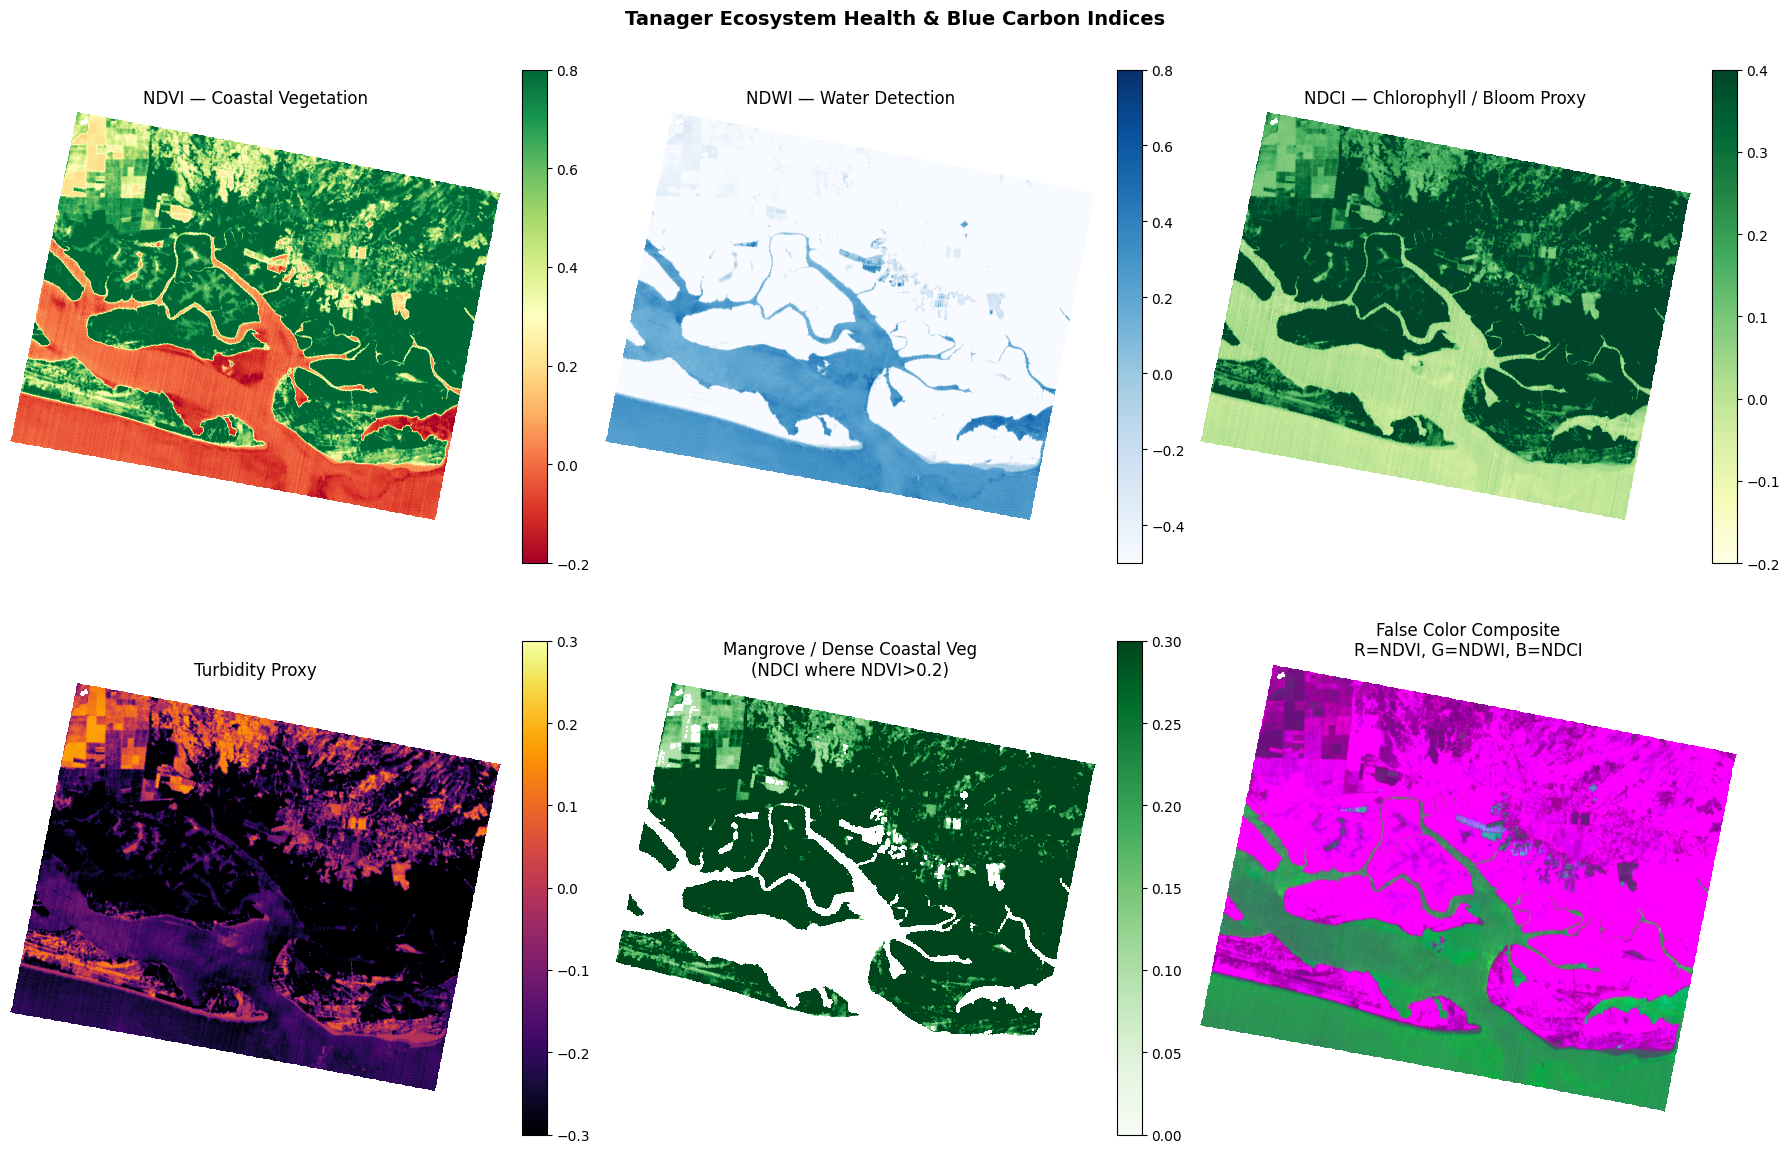

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

im1 = axes[0,0].imshow(NDVI, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
axes[0,0].set_title("NDVI — Coastal Vegetation"); axes[0,0].axis("off")
plt.colorbar(im1, ax=axes[0,0], fraction=0.046, pad=0.04)

im2 = axes[0,1].imshow(NDWI, cmap="Blues", vmin=-0.5, vmax=0.8)
axes[0,1].set_title("NDWI — Water Detection"); axes[0,1].axis("off")
plt.colorbar(im2, ax=axes[0,1], fraction=0.046, pad=0.04)

im3 = axes[0,2].imshow(NDCI, cmap="YlGn", vmin=-0.2, vmax=0.4)
axes[0,2].set_title("NDCI — Chlorophyll / Bloom Proxy"); axes[0,2].axis("off")
plt.colorbar(im3, ax=axes[0,2], fraction=0.046, pad=0.04)

im4 = axes[1,0].imshow(Turbidity, cmap="inferno", vmin=-0.3, vmax=0.3)
axes[1,0].set_title("Turbidity Proxy"); axes[1,0].axis("off")
plt.colorbar(im4, ax=axes[1,0], fraction=0.046, pad=0.04)

im5 = axes[1,1].imshow(Mangrove_proxy, cmap="Greens", vmin=0, vmax=0.3)
axes[1,1].set_title("Mangrove / Dense Coastal Veg\n(NDCI where NDVI>0.2)"); axes[1,1].axis("off")
plt.colorbar(im5, ax=axes[1,1], fraction=0.046, pad=0.04)

# False-color composite: R=NDVI, G=NDWI, B=NDCI
rgb = np.stack([
    np.clip((NDVI + 0.2) / 1.0, 0, 1),
    np.clip((NDWI + 0.5) / 1.3, 0, 1),
    np.clip((NDCI + 0.2) / 0.6, 0, 1)
], axis=-1)
axes[1,2].imshow(rgb)
axes[1,2].set_title("False Color Composite\nR=NDVI, G=NDWI, B=NDCI"); axes[1,2].axis("off")

plt.suptitle("Tanager Ecosystem Health & Blue Carbon Indices", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

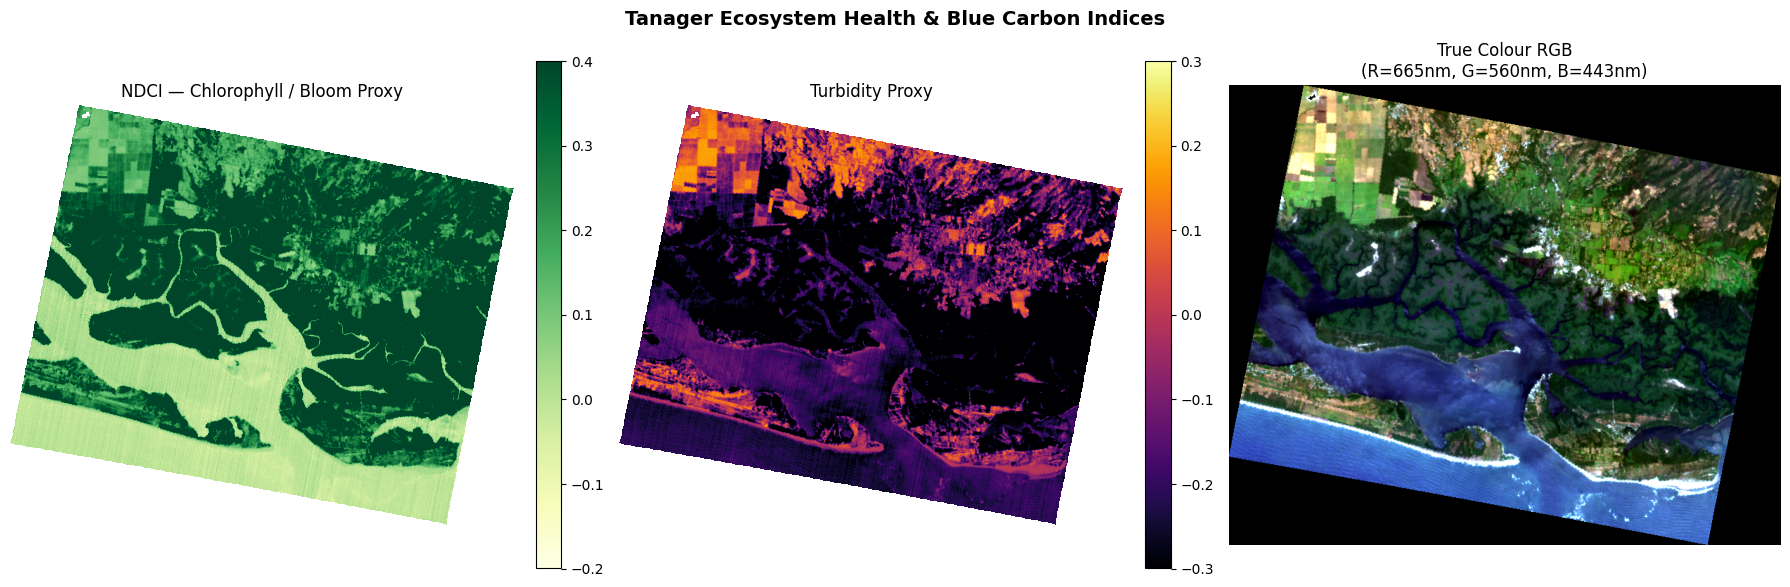

In [ ]:
# True RGB composite using Tanager surface reflectance bands
# R = 665 nm, G = 560 nm, B = 443 nm
# Percentile stretch so the image isn't washed out or too dark
def stretch(arr, p_low=2, p_high=98):
    lo, hi = np.nanpercentile(arr, p_low), np.nanpercentile(arr, p_high)
    return np.clip((arr - lo) / (hi - lo + 1e-6), 0, 1)

rgb_true = np.stack([
    stretch(R_665),   # Red channel
    stretch(R_560),   # Green channel
    stretch(R_443),   # Blue channel
], axis=-1)
# Replace NaN pixels with 0 for display
rgb_true = np.nan_to_num(rgb_true, nan=0.0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # was (18,12) — too tall for 1 row

im1 = axes[0].imshow(NDCI, cmap="YlGn", vmin=-0.2, vmax=0.4)
axes[0].set_title("NDCI — Chlorophyll / Bloom Proxy"); axes[0].axis("off")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)  # was im3 (wrong variable)

im2 = axes[1].imshow(Turbidity, cmap="inferno", vmin=-0.3, vmax=0.3)
axes[1].set_title("Turbidity Proxy"); axes[1].axis("off")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)  # was im4 (wrong variable)

axes[2].imshow(rgb_true)
axes[2].set_title("True Colour RGB\n(R=665nm, G=560nm, B=443nm)"); axes[2].axis("off")  # was axes[1,2] (wrong indexing for 1-row grid)

plt.suptitle("Tanager Ecosystem Health & Blue Carbon Indices", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

## Step 11 – Summary Statistics


In [ ]:
def summarize(name, arr):
    valid_data = arr[~np.isnan(arr)]
    if len(valid_data) == 0:
        print(f"{name}: no valid data")
        return
    print(f"{name}: min={valid_data.min():.3f}  max={valid_data.max():.3f}  "
          f"mean={valid_data.mean():.3f}  std={valid_data.std():.3f}")

summarize("NDVI",      NDVI)
summarize("NDWI",      NDWI)
summarize("NDCI",      NDCI)
summarize("Turbidity", Turbidity)

NDVI: min=-0.333  max=0.978  mean=0.496  std=0.369
NDWI: min=-0.847  max=0.632  mean=-0.373  std=0.416
NDCI: min=-0.176  max=0.874  mean=0.304  std=0.236
Turbidity: min=-0.846  max=0.223  mean=-0.230  std=0.164


## Step 12 – Mean Spectrum (Full Scene)

The spectral signature integrates all land cover types in the scene.
Look for the chlorophyll absorption dip at ~680 nm and the vegetation red-edge jump at ~720 nm.

We exclude the two water-vapor absorption troughs (1350–1450 nm, 1800–1950 nm) plus wavelengths beyond 2450 nm, where the SWIR2 detector's edge channels and the collapsing atmospheric window otherwise produce erratic reflectance spikes rather than real surface signal.

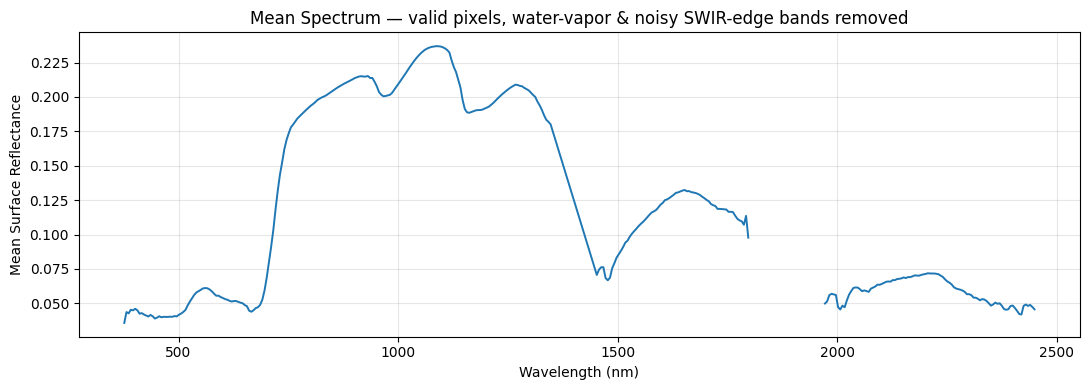

In [ ]:
def is_water_vapor(wl):
    return (1350 <= wl <= 1450) or (1800 <= wl <= 1950)

# Beyond ~2450 nm we're at the edge of the SWIR2 detector array: solar
# irradiance and atmospheric transmission both collapse toward the edge of
# the SWIR atmospheric window, and edge channels have the sensor's worst
# signal-to-noise ratio. Reflectance = radiance / irradiance blows up into
# noise there rather than showing real surface signal, so we drop that tail
# the same way we drop the water-vapor troughs.
SWIR_EDGE_NM = 2450

def is_bad_band(wl):
    return is_water_vapor(wl) or wl > SWIR_EDGE_NM

stride = 8
with h5py.File(local_path, "r") as f:
    sr = f[f"{root}/surface_reflectance"]
    good_idx = [i for i, w in enumerate(wavelengths_nm) if not is_bad_band(w)]
    cube = sr[good_idx, ::stride, ::stride].astype("float32")
    mask = valid[::stride, ::stride]
    cube[:, ~mask] = np.nan
    cube[cube < 0] = np.nan
    mean_spec = np.nanmean(cube, axis=(1,2))

wls = [wavelengths_nm[i] for i in good_idx]
plt.figure(figsize=(11,4))
plt.plot(wls, mean_spec, lw=1.4)
plt.xlabel("Wavelength (nm)"); plt.ylabel("Mean Surface Reflectance")
plt.title("Mean Spectrum — valid pixels, water-vapor & noisy SWIR-edge bands removed")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Spectral Signature of the Highest-Value Pixel per Index

The plot above shows the **scene-average** spectrum. Now let's look at individual pixels: for each index (NDVI, NDWI, NDCI, Turbidity), we find the single pixel with the *highest* value — e.g. the densest coastal vegetation (NDVI), the clearest open water (NDWI), the strongest chlorophyll/algal-bloom signal (NDCI), and the most sediment-laden water (Turbidity) — and plot its full spectral signature (water-vapor bands removed). Comparing these extreme-pixel spectra side by side shows how differently these land-cover conditions reflect light across the spectrum.

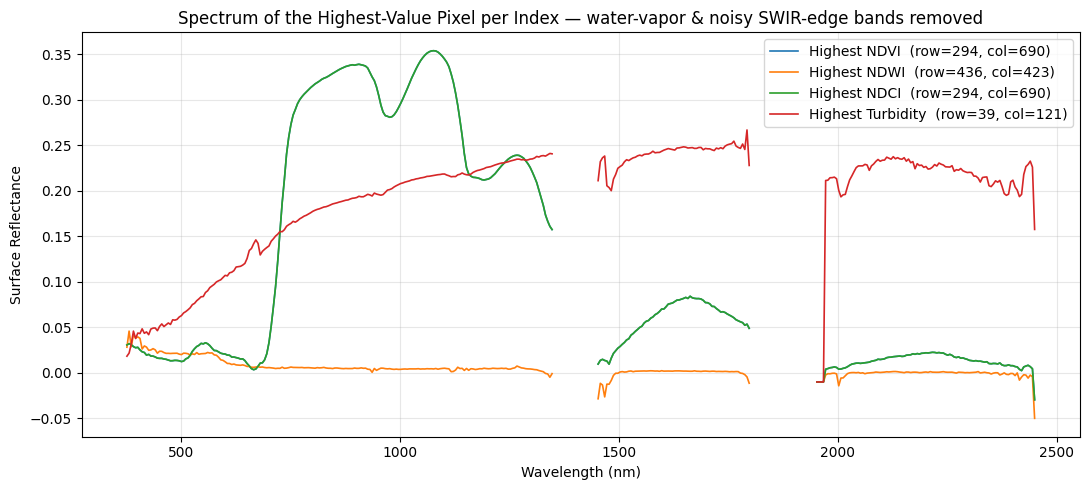

In [ ]:
# For the pixel with the single highest value of each index, read and plot its
# full spectral signature (reusing `good_idx`/`wls` from the cell above, which
# already exclude the water-vapor troughs and the noisy SWIR-edge tail).
#
# `good_idx` skips the excluded bands, so plain plt.plot(wls, ...) would draw
# a straight connecting line across those gaps. with_gaps() inserts a NaN
# wherever good_idx jumps by more than 1, so the line actually breaks there.
def with_gaps(band_idx, x, y):
    x_out, y_out = [x[0]], [y[0]]
    for k in range(1, len(band_idx)):
        if band_idx[k] != band_idx[k - 1] + 1:
            x_out.append((x[k - 1] + x[k]) / 2)
            y_out.append(np.nan)
        x_out.append(x[k]); y_out.append(y[k])
    return x_out, y_out

indices = {"NDVI": NDVI, "NDWI": NDWI, "NDCI": NDCI, "Turbidity": Turbidity}

plt.figure(figsize=(11, 5))
with h5py.File(local_path, "r") as f:
    sr = f[f"{root}/surface_reflectance"]
    for name, arr in indices.items():
        row, col = np.unravel_index(np.nanargmax(arr), arr.shape)
        pixel_spec = sr[good_idx, row, col].astype("float32")
        x_plot, y_plot = with_gaps(good_idx, wls, pixel_spec)
        plt.plot(x_plot, y_plot, lw=1.2, label=f"Highest {name}  (row={row}, col={col})")

plt.xlabel("Wavelength (nm)"); plt.ylabel("Surface Reflectance")
plt.title("Spectrum of the Highest-Value Pixel per Index — water-vapor & noisy SWIR-edge bands removed")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Step 13 – Water vs Vegetation Spectral Comparison

Compare the average spectrum of water pixels (NDWI > 0.1) vs vegetation pixels (NDVI > 0.3).


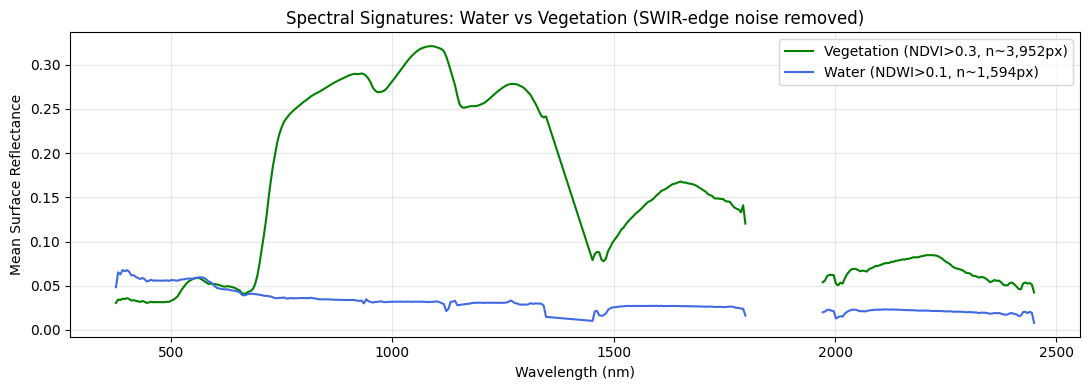

In [ ]:
stride = 8
def is_water_vapor(wl):
    return (1350 <= wl <= 1450) or (1800 <= wl <= 1950)

# Beyond ~2450 nm we're at the edge of the SWIR2 detector array: solar
# irradiance and atmospheric transmission both collapse toward the edge of
# the SWIR atmospheric window, and edge channels have the sensor's worst
# signal-to-noise ratio. Reflectance = radiance / irradiance blows up into
# noise there rather than showing real surface signal, so we drop that tail
# the same way we drop the water-vapor troughs.
SWIR_EDGE_NM = 2450

def is_bad_band(wl):
    return is_water_vapor(wl) or wl > SWIR_EDGE_NM

good_idx = [i for i, w in enumerate(wavelengths_nm) if not is_bad_band(w)]
wls = [wavelengths_nm[i] for i in good_idx]

water_mask = (NDWI > 0.1) & valid
veg_mask   = (NDVI > 0.3) & valid

def mean_spec(mask):
    with h5py.File(local_path, "r") as f:
        sr = f[f"{root}/surface_reflectance"]
        cube = sr[good_idx, ::stride, ::stride].astype("float32")
    m = mask[::stride, ::stride]
    cube[:, ~m] = np.nan
    cube[cube < 0] = np.nan
    return [float(np.nanmean(cube[j])) for j in range(len(good_idx))]

spec_water = mean_spec(water_mask)
spec_veg   = mean_spec(veg_mask)

plt.figure(figsize=(11, 4))
plt.plot(wls, spec_veg,   color="green",  lw=1.5, label=f"Vegetation (NDVI>0.3, n~{veg_mask.sum()//stride**2:,}px)")
plt.plot(wls, spec_water, color="royalblue", lw=1.5, label=f"Water (NDWI>0.1, n~{water_mask.sum()//stride**2:,}px)")
plt.xlabel("Wavelength (nm)"); plt.ylabel("Mean Surface Reflectance")
plt.title("Spectral Signatures: Water vs Vegetation (SWIR-edge noise removed)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [ ]:
%pip install pystac-client planetary-computer

In [ ]:
import requests

COLLECTION = "coastal-water-bodies"

item_ids = [
    "20250223_165546_32_4001",
    "20250511_074311_00_4001",
    "20250223_165546_32_4001",
    "20250406_170447_47_4001"
]

base = f"https://www.planet.com/data/stac/tanager-core-imagery/{COLLECTION}"

items = []

for iid in item_ids:
    url = f"{base}/{iid}/{iid}.json"
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    items.append(response.json())

item = items[0]

print("Scene metadata restored")
print("Bounding box:", item["bbox"])

Scene metadata restored
Bounding box: [-88.56425877863482, 13.139414553891845, -88.34746243694369, 13.316052417927148]


In [ ]:
from pystac_client import Client

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=item["bbox"],
    datetime="2024-01-01/2025-12-31",
    query={
        "eo:cloud_cover": {
            "lt": 20
        }
    }
)

sentinel_items = list(search.item_collection())

print("Sentinel-2 scenes found:", len(sentinel_items))

for s in sorted(sentinel_items, key=lambda x: x.datetime):
    print(
        s.datetime.date(),
        "cloud cover:",
        round(s.properties.get("eo:cloud_cover", 0), 1),
        "ID:",
        s.id
    )

Sentinel-2 scenes found: 69
2024-01-01 cloud cover: 0.0 ID: S2B_MSIL2A_20240101T161659_R140_T16PCV_20240101T211400
2024-01-06 cloud cover: 2.0 ID: S2A_MSIL2A_20240106T161651_R140_T16PCV_20240106T221245
2024-01-11 cloud cover: 14.8 ID: S2B_MSIL2A_20240111T161639_R140_T16PCV_20240116T183020
2024-01-11 cloud cover: 14.8 ID: S2B_MSIL2A_20240111T161639_R140_T16PCV_20240112T200952
2024-01-16 cloud cover: 0.0 ID: S2A_MSIL2A_20240116T161611_R140_T16PCV_20240116T221017
2024-01-21 cloud cover: 7.4 ID: S2B_MSIL2A_20240121T161559_R140_T16PCV_20240122T200934
2024-01-26 cloud cover: 0.1 ID: S2A_MSIL2A_20240126T161541_R140_T16PCV_20240126T222419
2024-01-31 cloud cover: 0.0 ID: S2B_MSIL2A_20240131T161509_R140_T16PCV_20240131T212158
2024-02-05 cloud cover: 1.9 ID: S2A_MSIL2A_20240205T161441_R140_T16PCV_20240205T222902
2024-02-10 cloud cover: 0.0 ID: S2B_MSIL2A_20240210T161419_R140_T16PCV_20240210T221924
2024-02-15 cloud cover: 0.0 ID: S2A_MSIL2A_20240215T161341_R140_T16PCV_20240215T223042
2024-02-20 cl

In [ ]:
def best_scene_for_month(items, year, month):
    candidates = [
        s for s in items
        if s.datetime.year == year
        and s.datetime.month == month
    ]

    if not candidates:
        raise ValueError(f"No scenes found for {year}-{month:02d}")

    return min(
        candidates,
        key=lambda s: s.properties.get("eo:cloud_cover", 100)
    )

baseline_s2 = best_scene_for_month(sentinel_items, 2024, 2)
later_s2 = best_scene_for_month(sentinel_items, 2025, 2)

print("Baseline scene:")
print(baseline_s2.datetime.date())
print("Cloud cover:", baseline_s2.properties.get("eo:cloud_cover"))

print("\nLater scene:")
print(later_s2.datetime.date())
print("Cloud cover:", later_s2.properties.get("eo:cloud_cover"))

Baseline scene:
2024-02-20
Cloud cover: 0.011301

Later scene:
2025-02-19
Cloud cover: 1.763292


In [ ]:
import planetary_computer
import rasterio
import numpy as np

def load_band(scene, band_name):
    signed_scene = planetary_computer.sign(scene)
    band_url = signed_scene.assets[band_name].href

    with rasterio.open(band_url) as src:
        data = src.read(1).astype("float32") / 10000.0

    return data

red_baseline = load_band(baseline_s2, "B04")
nir_baseline = load_band(baseline_s2, "B08")

red_later = load_band(later_s2, "B04")
nir_later = load_band(later_s2, "B08")

print("Bands loaded successfully")
print("Baseline shape:", red_baseline.shape)
print("Later shape:", red_later.shape)

Bands loaded successfully
Baseline shape: (10980, 10980)
Later shape: (10980, 10980)


In [ ]:
eps = 1e-6

ndvi_baseline = (
    (nir_baseline - red_baseline)
    / (nir_baseline + red_baseline + eps)
)

ndvi_later = (
    (nir_later - red_later)
    / (nir_later + red_later + eps)
)

ndvi_change = ndvi_later - ndvi_baseline

print("NDVI calculation complete")
print("Baseline mean NDVI:", np.nanmean(ndvi_baseline))
print("Later mean NDVI:", np.nanmean(ndvi_later))
print("Mean NDVI change:", np.nanmean(ndvi_change))

NDVI calculation complete
Baseline mean NDVI: 0.12190559
Later mean NDVI: 0.13055998
Mean NDVI change: 0.008653719


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

valid = np.isfinite(ndvi_change)

decreased = (ndvi_change < -0.10) & valid
increased = (ndvi_change > 0.10) & valid

print("Pixels with strong decrease:",
      round(decreased.sum() / valid.sum() * 100, 2), "%")

print("Pixels with strong increase:",
      round(increased.sum() / valid.sum() * 100, 2), "%")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(ndvi_baseline, cmap="RdYlGn", vmin=-0.5, vmax=0.8)
axes[0].set_title("Baseline NDVI - February 2024")
axes[0].axis("off")

axes[1].imshow(ndvi_later, cmap="RdYlGn", vmin=-0.5, vmax=0.8)
axes[1].set_title("Later NDVI - February 2025")
axes[1].axis("off")

im = axes[2].imshow(ndvi_change, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
axes[2].set_title("NDVI Change")
axes[2].axis("off")

plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

NameError: name 'ndvi_change' is not defined

Baseline: 2024-02-20
Later: 2025-02-19
Strong decrease: 1.99 %
Strong increase: 1.53 %


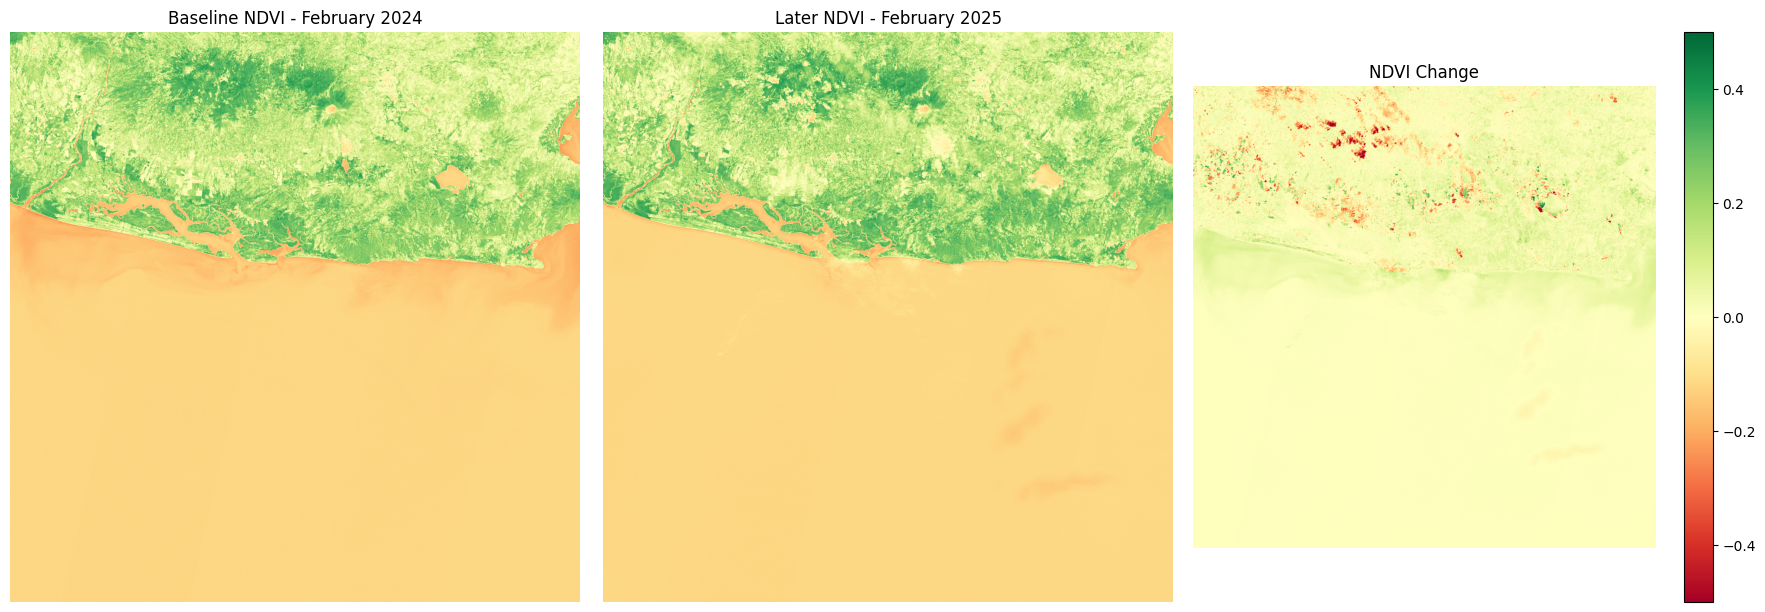

In [2]:
import requests
import numpy as np
import matplotlib.pyplot as plt
import planetary_computer
import rasterio

from pystac_client import Client
from rasterio.enums import Resampling

# 1. Restore the mangrove scene location
url = "https://www.planet.com/data/stac/tanager-core-imagery/coastal-water-bodies/20250223_165546_32_4001/20250223_165546_32_4001.json"

item = requests.get(url).json()
bbox = item["bbox"]

# 2. Search Sentinel-2 scenes
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2024-01-01/2025-12-31",
    query={"eo:cloud_cover": {"lt": 20}}
)

sentinel_items = list(search.item_collection())

def best_scene_for_month(items, year, month):
    candidates = [
        s for s in items
        if s.datetime.year == year and s.datetime.month == month
    ]
    return min(
        candidates,
        key=lambda s: s.properties.get("eo:cloud_cover", 100)
    )

baseline_s2 = best_scene_for_month(sentinel_items, 2024, 2)
later_s2 = best_scene_for_month(sentinel_items, 2025, 2)

print("Baseline:", baseline_s2.datetime.date())
print("Later:", later_s2.datetime.date())

# 3. Load smaller versions of the bands to avoid RAM crash
def load_band(scene, band_name):
    signed_scene = planetary_computer.sign(scene)
    band_url = signed_scene.assets[band_name].href

    with rasterio.open(band_url) as src:
        data = src.read(
            1,
            out_shape=(1, 1200, 1200),
            resampling=Resampling.bilinear
        ).astype("float32") / 10000.0

    return data

red_baseline = load_band(baseline_s2, "B04")
nir_baseline = load_band(baseline_s2, "B08")
red_later = load_band(later_s2, "B04")
nir_later = load_band(later_s2, "B08")

# 4. Calculate NDVI change
eps = 1e-6

ndvi_baseline = (nir_baseline - red_baseline) / (
    nir_baseline + red_baseline + eps
)

ndvi_later = (nir_later - red_later) / (
    nir_later + red_later + eps
)

ndvi_change = ndvi_later - ndvi_baseline

valid = np.isfinite(ndvi_change)
decreased = (ndvi_change < -0.10) & valid
increased = (ndvi_change > 0.10) & valid

print("Strong decrease:",
      round(decreased.sum() / valid.sum() * 100, 2), "%")

print("Strong increase:",
      round(increased.sum() / valid.sum() * 100, 2), "%")

# 5. Display the three maps
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(ndvi_baseline, cmap="RdYlGn", vmin=-0.5, vmax=0.8)
axes[0].set_title("Baseline NDVI - February 2024")
axes[0].axis("off")

axes[1].imshow(ndvi_later, cmap="RdYlGn", vmin=-0.5, vmax=0.8)
axes[1].set_title("Later NDVI - February 2025")
axes[1].axis("off")

im = axes[2].imshow(ndvi_change, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
axes[2].set_title("NDVI Change")
axes[2].axis("off")

plt.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

In [1]:
import os
import glob
import io
import zipfile
import requests
import rasterio
from rasterio.merge import merge

# Find existing GMW files
all_gmw_files = glob.glob(
    "gmw_2020/**/*.tif",
    recursive=True
)

# Download GMW files if missing
if len(all_gmw_files) == 0:
    print("GMW files not found. Downloading again...")

    record = requests.get(
        "https://zenodo.org/api/records/6894273"
    ).json()

    file_info = next(
        f for f in record["files"]
        if f["key"] == "gmw_v3_2020_gtiff.zip"
    )

    response = requests.get(
        file_info["links"]["self"]
    )
    response.raise_for_status()

    with zipfile.ZipFile(
        io.BytesIO(response.content)
    ) as z:
        z.extractall("gmw_2020")

    all_gmw_files = glob.glob(
        "gmw_2020/**/*.tif",
        recursive=True
    )

# GCC bounding box:
# Kuwait, Saudi Arabia, Bahrain, Qatar, UAE and Oman
gcc_bbox = (
    34.0,  # west
    16.0,  # south
    60.5,  # east
    31.5   # north
)

gcc_files = []

# Select GMW tiles covering the GCC
for file in all_gmw_files:
    with rasterio.open(file) as src:
        bounds = src.bounds

        overlaps_gcc = (
            bounds.right >= gcc_bbox[0]
            and bounds.left <= gcc_bbox[2]
            and bounds.top >= gcc_bbox[1]
            and bounds.bottom <= gcc_bbox[3]
        )

        if overlaps_gcc:
            gcc_files.append(file)

print("Total TIFF files:", len(all_gmw_files))
print("GCC tiles:", len(gcc_files))

if len(gcc_files) == 0:
    raise ValueError("No GMW tiles found for the GCC region.")

# Merge GCC tiles
sources = [
    rasterio.open(file)
    for file in gcc_files
]

gcc_crs = sources[0].crs

mosaic, transform = merge(sources)

for source in sources:
    source.close()

print("GCC GMW mosaic successfully created.")
print("Mosaic shape:", mosaic.shape)
print("GCC CRS:", gcc_crs)

Total TIFF files: 1521
GCC tiles: 60
GCC GMW mosaic successfully created.
Mosaic shape: (1, 63000, 117000)
GCC CRS: EPSG:4326


In [2]:
import json
import numpy as np
from rasterio.transform import xy

# Sample every 20th pixel to keep the GeoJSON lightweight
sample_step = 20

gcc_data = mosaic[0][::sample_step, ::sample_step]

rows, cols = np.where(gcc_data == 1)

features = []

for row, col in zip(rows, cols):
    original_row = row * sample_step
    original_col = col * sample_step

    longitude, latitude = xy(
        transform,
        original_row,
        original_col,
        offset="center"
    )

    features.append({
        "type": "Feature",
        "geometry": {
            "type": "Point",
            "coordinates": [
                float(longitude),
                float(latitude)
            ]
        },
        "properties": {
            "region": "GCC",
            "source": "Global Mangrove Watch 2020"
        }
    })

gcc_geojson = {
    "type": "FeatureCollection",
    "features": features
}

with open("gcc_mangrove_analysis_points.geojson", "w") as f:
    json.dump(gcc_geojson, f)

print("GCC GeoJSON created.")
print("Mangrove points:", len(features))
print("File: gcc_mangrove_analysis_points.geojson")

GCC GeoJSON created.
Mangrove points: 1290
File: gcc_mangrove_analysis_points.geojson


In [4]:
import json
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from rasterio.transform import xy

# Load country boundaries
countries_url = (
    "https://raw.githubusercontent.com/"
    "nvkelso/natural-earth-vector/master/geojson/"
    "ne_110m_admin_0_countries.geojson"
)

world = gpd.read_file(countries_url)

# Exact GCC countries
gcc_country_names = [
    "Saudi Arabia",
    "United Arab Emirates",
    "Oman",
    "Qatar",
    "Bahrain",
    "Kuwait"
]

gcc_countries = world[
    world["ADMIN"].isin(gcc_country_names)
]

# Combine the six GCC country boundaries
gcc_geometry = gcc_countries.geometry.unary_union

# Sample every 20th GMW pixel
sample_step = 20
gcc_data = mosaic[0][::sample_step, ::sample_step]

rows, cols = np.where(gcc_data == 1)

features = []

for row, col in zip(rows, cols):
    original_row = row * sample_step
    original_col = col * sample_step

    longitude, latitude = xy(
        transform,
        original_row,
        original_col,
        offset="center"
    )

    point = Point(longitude, latitude)

    # Keep only points inside actual GCC countries
    if gcc_geometry.covers(point):
        features.append({
            "type": "Feature",
            "geometry": {
                "type": "Point",
                "coordinates": [
                    float(longitude),
                    float(latitude)
                ]
            },
            "properties": {
                "region": "GCC",
                "source": "Global Mangrove Watch 2020"
            }
        })

gcc_geojson = {
    "type": "FeatureCollection",
    "features": features
}

with open("gcc_mangrove_analysis_points.geojson", "w") as f:
    json.dump(gcc_geojson, f)

print("Corrected GCC GeoJSON created.")
print("GCC mangrove points:", len(features))
print("File: gcc_mangrove_analysis_points.geojson")

/tmp/ipykernel_63626/4119148406.py:31: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  gcc_geometry = gcc_countries.geometry.unary_union


Corrected GCC GeoJSON created.
GCC mangrove points: 475
File: gcc_mangrove_analysis_points.geojson


In [ ]:
import glob
import rasterio
from rasterio.merge import merge

# Find all GMW tiles
all_gmw_files = glob.glob(
    "gmw_2020/**/*.tif",
    recursive=True
)

print("GMW files found:", len(all_gmw_files))

# UAE bounding box
uae_bbox = (51, 22, 56.5, 26.5)

uae_files = []

for file in all_gmw_files:
    with rasterio.open(file) as src:
        bounds = src.bounds

        if (
            bounds.right >= uae_bbox[0]
            and bounds.left <= uae_bbox[2]
            and bounds.top >= uae_bbox[1]
            and bounds.bottom <= uae_bbox[3]
        ):
            uae_files.append(file)

print("UAE tiles found:", len(uae_files))

# Merge the UAE tiles
sources = [rasterio.open(file) for file in uae_files]

mosaic, transform = merge(sources)

for source in sources:
    source.close()

print("GMW mosaic restored.")
print("Mosaic shape:", mosaic.shape)

GMW files found: 1521
UAE tiles found: 11
GMW mosaic restored.
Mosaic shape: (1, 18000, 27000)


In [6]:
import numpy as np
from pyproj import Transformer
from rasterio.transform import from_bounds
from rasterio.enums import Resampling
from rasterio.warp import reproject

# Output grid size
output_height, output_width = ndvi_later.shape

# UAE Sentinel-2 tile 40RBN uses UTM zone 40N
sentinel_crs = "EPSG:32640"

# Get the corrected UAE scene bbox
min_lon, min_lat, max_lon, max_lat = later_s2.bbox

# Convert the bbox from longitude/latitude to UTM zone 40N
bbox_transformer = Transformer.from_crs(
    "EPSG:4326",
    sentinel_crs,
    always_xy=True
)

corners = [
    bbox_transformer.transform(min_lon, min_lat),
    bbox_transformer.transform(min_lon, max_lat),
    bbox_transformer.transform(max_lon, min_lat),
    bbox_transformer.transform(max_lon, max_lat)
]

x_values = [point[0] for point in corners]
y_values = [point[1] for point in corners]

projected_bounds = (
    min(x_values),
    min(y_values),
    max(x_values),
    max(y_values)
)

sentinel_transform = from_bounds(
    *projected_bounds,
    width=output_width,
    height=output_height
)

# Create a mask matching the Sentinel grid
gmw_mask_on_sentinel = np.zeros(
    (output_height, output_width),
    dtype="uint8"
)

# Reproject GMW onto the corrected Sentinel grid
reproject(
    source=mosaic[0].astype("uint8"),
    destination=gmw_mask_on_sentinel,
    src_transform=transform,
    src_crs="EPSG:4326",
    dst_transform=sentinel_transform,
    dst_crs=sentinel_crs,
    resampling=Resampling.nearest,
    src_nodata=0,
    dst_nodata=0
)

# Keep only valid mangrove pixels
mangrove_pixels = (
    (gmw_mask_on_sentinel == 1)
    & np.isfinite(ndvi_later)
)

mangrove_ndvi = ndvi_later[mangrove_pixels]

print("Corrected Sentinel CRS:", sentinel_crs)
print("GMW mangrove pixels found:", len(mangrove_ndvi))

Corrected Sentinel CRS: EPSG:32640
GMW mangrove pixels found: 0


In [7]:
from rasterio.transform import array_bounds

print("Sentinel bounds:")
print(
    array_bounds(
        ndvi_later.shape[0],
        ndvi_later.shape[1],
        sentinel_transform
    )
)

print("\nGMW bounds:")
print(
    array_bounds(
        mosaic.shape[1],
        mosaic.shape[2],
        transform
    )
)

print("\nGMW non-mangrove/mangrove pixel counts:")
print(np.unique(mosaic, return_counts=True))

print("\nReprojected GMW pixels:")
print(int(np.sum(gmw_mask_on_sentinel == 1)))

Sentinel bounds:
(-3557548.8478118633, 18174896.53934531, -3405863.1329671196, 18326578.987029746)

GMW bounds:
(51.0, 23.000000000004, 56.999999999994, 27.0)

GMW non-mangrove/mangrove pixel counts:
(array([0, 1], dtype=uint8), array([485734323,    265677]))

Reprojected GMW pixels:
0


In [9]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.transform import from_bounds

# Correct CRS for Sentinel-2 tile 40RBN
sentinel_crs = "EPSG:32640"

# Use the exact later scene dimensions
height, width = ndvi_later.shape

# Convert the STAC geographic bounds to correct UTM bounds
min_lon, min_lat, max_lon, max_lat = later_s2.bbox

projected_bounds = transform_bounds(
    "EPSG:4326",
    sentinel_crs,
    min_lon,
    min_lat,
    max_lon,
    max_lat
)

print("Projected Sentinel bounds:")
print(projected_bounds)

# Create a valid Sentinel transform
sentinel_transform = from_bounds(
    *projected_bounds,
    width=width,
    height=height
)

# Reproject the UAE GMW mosaic onto the Sentinel grid
gmw_on_sentinel = np.zeros((height, width), dtype=np.uint8)

reproject(
    source=gmw_mosaic[0],
    destination=gmw_on_sentinel,
    src_transform=gmw_transform,
    src_crs=gmw_crs,
    dst_transform=sentinel_transform,
    dst_crs=sentinel_crs,
    resampling=Resampling.nearest,
    dst_nodata=0
)

gmw_mask = gmw_on_sentinel == 1

print("GMW mangrove pixels found:", int(gmw_mask.sum()))

Projected Sentinel bounds:
(-3557548.8478118633, 18174896.53934531, -3405863.1329671196, 18326578.987029746)


NameError: name 'gmw_mosaic' is not defined

In [5]:
from rasterio.transform import array_bounds

print("Sentinel CRS:")
print(sentinel_crs)

print("\nSentinel bounds:")
print(
    array_bounds(
        ndvi_later.shape[0],
        ndvi_later.shape[1],
        sentinel_transform
    )
)

print("\nGMW CRS:")
print("EPSG:4326")

print("\nGMW bounds:")
print(
    array_bounds(
        mosaic.shape[1],
        mosaic.shape[2],
        transform
    )
)

print("\nGMW unique values:")
print(np.unique(mosaic))

Sentinel CRS:
EPSG:32616

Sentinel bounds:
(300000.0, 1390200.0, 409800.0, 1500000.0)

GMW CRS:
EPSG:4326

GMW bounds:
(51.0, 23.000000000004, 56.999999999994, 27.0)

GMW unique values:
[0 1]


In [ ]:
import rasterio
import planetary_computer
from rasterio.enums import Resampling

# Load Sentinel-2 Green band B03 for the later date
signed_later = planetary_computer.sign(later_s2)

with rasterio.open(signed_later.assets["B03"].href) as src:
    green_later = src.read(
        1,
        out_shape=(ndvi_later.shape[0], ndvi_later.shape[1]),
        resampling=Resampling.bilinear
    ).astype("float32")

# Calculate NDWI
eps = 1e-6

ndwi_later = (
    green_later - nir_later
) / (
    green_later + nir_later + eps
)

# Keep only GMW mangrove areas
mangrove_ndwi = ndwi_later[mangrove_pixels]

print("Mangrove mean NDWI:",
      round(float(np.nanmean(mangrove_ndwi)), 3))

print("Mangrove median NDWI:",
      round(float(np.nanmedian(mangrove_ndwi)), 3))

Mangrove mean NDWI: -1.0
Mangrove median NDWI: -1.0


In [ ]:
print("Green band minimum:", np.nanmin(green_later))
print("Green band maximum:", np.nanmax(green_later))

print("NIR band minimum:", np.nanmin(nir_later))
print("NIR band maximum:", np.nanmax(nir_later))

print("Green zero pixels:",
      np.sum(green_later == 0))

print("NIR zero pixels:",
      np.sum(nir_later == 0))

Green band minimum: 0.0
Green band maximum: 1710.0
NIR band minimum: 0.0464
NIR band maximum: 1.7858
Green zero pixels: 1347085
NIR zero pixels: 0


In [ ]:
# Correct the Green band scale
green_later_scaled = green_later / 10000.0

# Valid NDWI pixels inside GMW mangroves
valid_ndwi_pixels = (
    mangrove_pixels
    & (green_later_scaled > 0)
    & np.isfinite(nir_later)
)

# Calculate corrected NDWI
eps = 1e-6

ndwi_later_corrected = (
    green_later_scaled - nir_later
) / (
    green_later_scaled + nir_later + eps
)

mangrove_ndwi_corrected = ndwi_later_corrected[
    valid_ndwi_pixels
]

print("Valid mangrove NDWI pixels:",
      len(mangrove_ndwi_corrected))

print("Corrected mean NDWI:",
      round(float(np.nanmean(mangrove_ndwi_corrected)), 3))

print("Corrected median NDWI:",
      round(float(np.nanmedian(mangrove_ndwi_corrected)), 3))

Valid mangrove NDWI pixels: 0
Corrected mean NDWI: nan
Corrected median NDWI: nan


/tmp/ipykernel_1939/300003538.py:28: RuntimeWarning: Mean of empty slice
  round(float(np.nanmean(mangrove_ndwi_corrected)), 3))
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


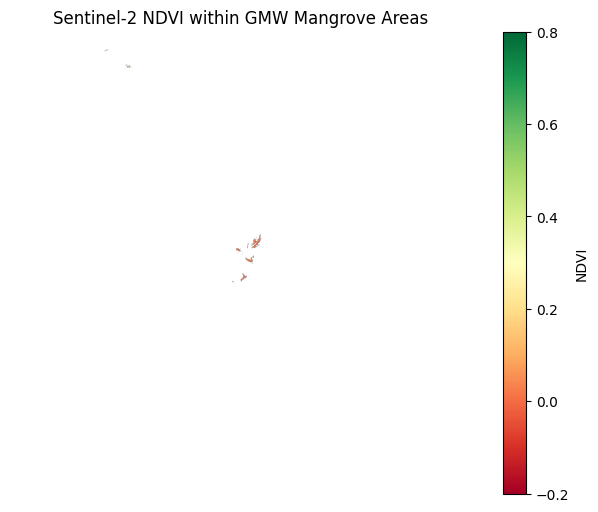

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

mangrove_ndvi_map = np.where(
    mangrove_pixels,
    ndvi_later,
    np.nan
)

plt.figure(figsize=(8, 6))

plt.imshow(
    mangrove_ndvi_map,
    cmap="RdYlGn",
    vmin=-0.2,
    vmax=0.8
)

plt.colorbar(label="NDVI")
plt.title("Sentinel-2 NDVI within GMW Mangrove Areas")
plt.axis("off")
plt.show()

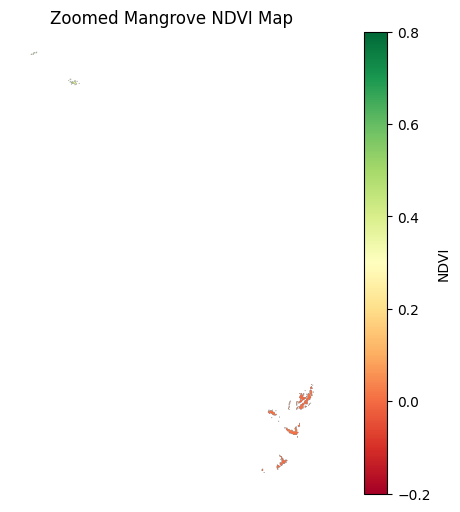

In [ ]:
rows, cols = np.where(np.isfinite(mangrove_ndvi_map))

if len(rows) > 0:
    padding = 30

    r_min = max(rows.min() - padding, 0)
    r_max = min(rows.max() + padding, mangrove_ndvi_map.shape[0])

    c_min = max(cols.min() - padding, 0)
    c_max = min(cols.max() + padding, mangrove_ndvi_map.shape[1])

    cropped_map = mangrove_ndvi_map[
        r_min:r_max,
        c_min:c_max
    ]

    plt.figure(figsize=(8, 6))

    plt.imshow(
        cropped_map,
        cmap="RdYlGn",
        vmin=-0.2,
        vmax=0.8
    )

    plt.colorbar(label="NDVI")
    plt.title("Zoomed Mangrove NDVI Map")
    plt.axis("off")
    plt.show()

else:
    print("No mangrove pixels available.")

In [ ]:
# Calculate a relative health score from the observed mangrove NDVI range

p10, p90 = np.nanpercentile(mangrove_ndvi, [10, 90])

relative_health_score = np.clip(
    (mangrove_mean_ndvi - p10) / (p90 - p10) * 100,
    0,
    100
)

print("Mangrove NDVI 10th percentile:", round(p10, 3))
print("Mangrove NDVI 90th percentile:", round(p90, 3))
print("Relative mangrove health score:",
      round(relative_health_score, 1), "/ 100")

Mangrove NDVI 10th percentile: -0.004
Mangrove NDVI 90th percentile: 0.025
Relative mangrove health score: 100.0 / 100


In [ ]:
# Robust health score using the median NDVI

median_ndvi = np.nanmedian(mangrove_ndvi)
p10, p90 = np.nanpercentile(mangrove_ndvi, [10, 90])

robust_health_score = np.clip(
    (median_ndvi - p10) / (p90 - p10) * 100,
    0,
    100
)

print("Mangrove pixel count:", len(mangrove_ndvi))
print("NDVI minimum:", round(np.nanmin(mangrove_ndvi), 3))
print("NDVI median:", round(median_ndvi, 3))
print("NDVI maximum:", round(np.nanmax(mangrove_ndvi), 3))
print("Robust health score:",
      round(robust_health_score, 1), "/ 100")

Mangrove pixel count: 535
NDVI minimum: -0.017
NDVI median: 0.004
NDVI maximum: 0.584
Robust health score: 27.6 / 100


In [ ]:
# Change detection only inside GMW mangrove areas

mangrove_change = ndvi_change[mangrove_pixels]

mean_change = np.nanmean(mangrove_change)

decreased = mangrove_change < -0.10
stable = (
    (mangrove_change >= -0.10)
    & (mangrove_change <= 0.10)
)
increased = mangrove_change > 0.10

print("Mean mangrove NDVI change:", round(mean_change, 3))
print("Possible decrease:",
      round(decreased.mean() * 100, 2), "%")
print("Stable:",
      round(stable.mean() * 100, 2), "%")
print("Possible increase:",
      round(increased.mean() * 100, 2), "%")

Mean mangrove NDVI change: 0.007
Possible decrease: 0.37 %
Stable: 99.63 %
Possible increase: 0.0 %


In [ ]:
import json
import numpy as np
import rasterio
from pyproj import Transformer

# Find mangrove pixel positions
rows, cols = np.where(mangrove_pixels)

# Convert Sentinel pixel coordinates to map coordinates
x_coords, y_coords = rasterio.transform.xy(
    sentinel_transform,
    rows,
    cols
)

# Convert Sentinel CRS to latitude/longitude
transformer = Transformer.from_crs(
    sentinel_crs,
    "EPSG:4326",
    always_xy=True
)

longitudes, latitudes = transformer.transform(
    x_coords,
    y_coords
)

features = []

for i in range(len(rows)):
    ndvi_value = float(ndvi_later[rows[i], cols[i]])
    change_value = float(ndvi_change[rows[i], cols[i]])

    # Calculate a pixel-level health score
    pixel_health_score = np.clip(
        (ndvi_value - p10) / (p90 - p10) * 100,
        0,
        100
    )

    if change_value < -0.10:
        change_status = "Possible decrease"
        action = "Field or UAV inspection recommended"
    elif change_value > 0.10:
        change_status = "Possible increase"
        action = "Continue monitoring"
    else:
        change_status = "Stable"
        action = "Continue monitoring"

    feature = {
        "type": "Feature",
        "geometry": {
            "type": "Point",
            "coordinates": [
                float(longitudes[i]),
                float(latitudes[i])
            ]
        },
        "properties": {
            "ndvi": round(ndvi_value, 4),
            "ndvi_change": round(change_value, 4),
            "health_score": round(float(pixel_health_score), 1),
            "change_status": change_status,
            "recommended_action": action
        }
    }

    features.append(feature)

analysis_geojson = {
    "type": "FeatureCollection",
    "features": features
}

with open("mangrove_analysis_points.geojson", "w") as file:
    json.dump(analysis_geojson, file, indent=2)

print("Location-specific analysis file created.")
print("Number of points:", len(features))

Location-specific analysis file created.
Number of points: 535


In [ ]:
import json
import numpy as np
import rasterio
from pyproj import Transformer

# ---------------------------------
# Create corrected UAE analysis points
# ---------------------------------

# Use the corrected UAE Sentinel-2 scene footprint
min_lon, min_lat, max_lon, max_lat = later_s2.bbox

# Convert scene bbox from longitude/latitude to Sentinel CRS
bbox_transformer = Transformer.from_crs(
    "EPSG:4326",
    sentinel_crs,
    always_xy=True
)

bbox_corners = [
    bbox_transformer.transform(min_lon, min_lat),
    bbox_transformer.transform(min_lon, max_lat),
    bbox_transformer.transform(max_lon, min_lat),
    bbox_transformer.transform(max_lon, max_lat)
]

x_values = [point[0] for point in bbox_corners]
y_values = [point[1] for point in bbox_corners]

projected_bounds = (
    min(x_values),
    min(y_values),
    max(x_values),
    max(y_values)
)

# Create transform matching the NDVI array dimensions
analysis_transform = rasterio.transform.from_bounds(
    *projected_bounds,
    width=ndvi_later.shape[1],
    height=ndvi_later.shape[0]
)

# Find mangrove pixel locations
rows, cols = np.where(mangrove_pixels)

# Convert pixel positions to projected coordinates
x_coords, y_coords = rasterio.transform.xy(
    analysis_transform,
    rows,
    cols
)

# Convert projected coordinates to longitude/latitude
coordinate_transformer = Transformer.from_crs(
    sentinel_crs,
    "EPSG:4326",
    always_xy=True
)

longitudes, latitudes = coordinate_transformer.transform(
    x_coords,
    y_coords
)

features = []

for i in range(len(rows)):
    row = rows[i]
    col = cols[i]

    ndvi_value = float(ndvi_later[row, col])
    change_value = float(ndvi_change[row, col])

    pixel_health_score = np.clip(
        (ndvi_value - p10) / (p90 - p10) * 100,
        0,
        100
    )

    if change_value < -0.10:
        change_status = "Possible decrease"
        action = "Field or UAV inspection recommended"
    elif change_value > 0.10:
        change_status = "Possible increase"
        action = "Continue monitoring"
    else:
        change_status = "Stable"
        action = "Continue monitoring"

    feature = {
        "type": "Feature",
        "geometry": {
            "type": "Point",
            "coordinates": [
                float(longitudes[i]),
                float(latitudes[i])
            ]
        },
        "properties": {
            "ndvi": round(ndvi_value, 4),
            "ndvi_change": round(change_value, 4),
            "health_score": round(float(pixel_health_score), 1),
            "change_status": change_status,
            "recommended_action": action
        }
    }

    features.append(feature)

analysis_geojson = {
    "type": "FeatureCollection",
    "features": features
}

with open("mangrove_analysis_points.geojson", "w") as file:
    json.dump(analysis_geojson, file, indent=2)

print("Corrected GeoJSON created.")
print("Number of points:", len(features))
print(
    "Longitude range:",
    round(min(longitudes), 4),
    "to",
    round(max(longitudes), 4)
)
print(
    "Latitude range:",
    round(min(latitudes), 4),
    "to",
    round(max(latitudes), 4)
)

Corrected GeoJSON created.
Number of points: 535
Longitude range: 54.7102 to 54.8772
Latitude range: 26.0015 to 26.2021


In [ ]:
mangrove_site_bbox = [
    54.2,  # west
    24.2,  # south
    54.8,  # east
    25.0   # north
]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=mangrove_site_bbox,
    datetime="2025-02-01/2025-03-10",
    query={
        "eo:cloud_cover": {"lt": 20}
    }
)

items = list(search.get_items())

for item in items[:20]:
    print(
        "Tile:",
        item.properties.get("s2:mgrs_tile"),
        "| BBox:",
        item.bbox,
        "| Cloud:",
        item.properties.get("eo:cloud_cover")
    )

Tile: 40QBM | BBox: [54.057938, 23.3940929, 55.1384076, 24.4018062] | Cloud: 12.758613
Tile: 39QZG | BBox: [53.9880841, 23.370268, 55.0379466, 24.3784925] | Cloud: 10.632485
Tile: 40RBN | BBox: [54.0207551, 24.2963214, 54.923768, 25.3015403] | Cloud: 4.687841
Tile: 40QBM | BBox: [54.0422865, 23.3940929, 54.6831214, 24.3947655] | Cloud: 15.649487
Tile: 39RZH | BBox: [53.9552702, 24.2802654, 54.9138425, 25.2866352] | Cloud: 5.040298
Tile: 39QZG | BBox: [53.9348686, 23.3833612, 54.6760412, 24.3845428] | Cloud: 15.862267
Tile: 40RBN | BBox: [54.2050869, 24.298879, 55.1254532, 25.3046239] | Cloud: 0.510401
Tile: 40QBM | BBox: [54.0582026, 23.3940929, 55.1384076, 24.4018062] | Cloud: 0.294842
Tile: 39RZH | BBox: [54.2031149, 24.2714638, 55.0672962, 25.2756253] | Cloud: 0.589751
Tile: 39QZG | BBox: [53.9895855, 23.370268, 55.0379466, 24.3783795] | Cloud: 0.300014
Tile: 40RBN | BBox: [54.0207551, 24.2963214, 54.9227511, 25.3015235] | Cloud: 2.133414
Tile: 40QBM | BBox: [54.0422865, 23.6277181,

In [ ]:
def get_same_tile_scene(start_date, end_date, tile_name):
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=uae_bbox,
        datetime=f"{start_date}/{end_date}",
        query={
            "eo:cloud_cover": {"lt": 20},
            "s2:mgrs_tile": {"eq": tile_name}
        }
    )

    items = list(search.get_items())

    if len(items) == 0:
        raise ValueError("No matching UAE scene found.")

    items = sorted(
        items,
        key=lambda item: item.properties.get("eo:cloud_cover", 100)
    )

    item = items[0]

    print("Scene:", item.id)
    print("Tile:", item.properties.get("s2:mgrs_tile"))
    print("BBox:", item.bbox)
    print("Cloud cover:", item.properties.get("eo:cloud_cover"))

    return item


baseline_s2 = get_same_tile_scene(
    "2024-02-01",
    "2024-03-10",
    "40RBN"
)

later_s2 = get_same_tile_scene(
    "2025-02-01",
    "2025-03-10",
    "40RBN"
)

Scene: S2B_MSIL2A_20240222T064909_R020_T40RBN_20240222T114638
Tile: 40RBN
BBox: [54.20888836, 24.29893944, 55.1254532, 25.30462389]
Cloud cover: 0.352228
Scene: S2C_MSIL2A_20250204T070131_R063_T40RBN_20250204T101810
Tile: 40RBN
BBox: [54.0207551, 24.2963214, 54.9199956, 25.301478]
Cloud cover: 0.231268


In [ ]:
# Search only around the Abu Dhabi mangrove study area

abu_dhabi_bbox = [
    54.0,  # west
    24.0,  # south
    55.0,  # east
    25.5   # north
]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=abu_dhabi_bbox,
    datetime="2025-02-01/2025-03-10",
    query={
        "eo:cloud_cover": {"lt": 20}
    }
)

items = list(search.get_items())

items = sorted(
    items,
    key=lambda item: item.properties.get("eo:cloud_cover", 100)
)

print("Candidate UAE scenes:")

for item in items[:10]:
    print(
        "Tile:",
        item.properties.get("s2:mgrs_tile"),
        "| BBox:",
        item.bbox,
        "| Cloud:",
        item.properties.get("eo:cloud_cover")
    )

Candidate UAE scenes:
Tile: 39RYJ | BBox: [52.9847884, 25.1964494, 54.0991788, 26.2060005] | Cloud: 0.003843
Tile: 39RZJ | BBox: [54.4168769, 25.1725214, 55.0980918, 26.1724574] | Cloud: 0.005752
Tile: 40RBP | BBox: [54.4209875, 25.2049787, 55.1118476, 26.2073238] | Cloud: 0.010318
Tile: 40RBP | BBox: [54.4348456, 25.2052068, 55.1118476, 26.0784415] | Cloud: 0.0111
Tile: 39RZJ | BBox: [54.4305895, 25.1725214, 55.0928621, 26.0784415] | Cloud: 0.015043
Tile: 40RBP | BBox: [54.4224863, 25.2050034, 55.1118476, 26.2073238] | Cloud: 0.022446
Tile: 39RZJ | BBox: [54.4183742, 25.1725214, 55.0980918, 26.1724096] | Cloud: 0.024171
Tile: 39RYH | BBox: [52.9704875, 24.2944248, 54.075856, 25.3033526] | Cloud: 0.052643
Tile: 39QYG | BBox: [52.9568711, 23.3922752, 54.053629, 24.4005861] | Cloud: 0.1081
Tile: 39RZJ | BBox: [53.9766967, 25.1767549, 55.0980918, 26.1885994] | Cloud: 0.151859


In [ ]:
from google.colab import files

files.download("mangrove_analysis_points.geojson")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

mangrove_site_bbox = [
    54.2,  # west
    24.2,  # south
    54.8,  # east
    25.0   # north
]

def get_mangrove_scene(start_date, end_date):
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=mangrove_site_bbox,
        datetime=f"{start_date}/{end_date}",
        query={
            "eo:cloud_cover": {"lt": 20},
            "s2:mgrs_tile": {"eq": "40RBN"}
        }
    )

    items = list(search.item_collection())

    if not items:
        raise ValueError("No 40RBN scene found.")

    items = sorted(
        items,
        key=lambda item: item.properties.get("eo:cloud_cover", 100)
    )

    scene = items[0]

    print("Scene:", scene.id)
    print("Tile:", scene.properties.get("s2:mgrs_tile"))
    print("BBox:", scene.bbox)
    print("Cloud cover:", scene.properties.get("eo:cloud_cover"))

    return scene


baseline_s2 = get_mangrove_scene(
    "2024-02-01",
    "2024-03-10"
)

later_s2 = get_mangrove_scene(
    "2025-02-01",
    "2025-03-10"
)

Scene: S2B_MSIL2A_20240222T064909_R020_T40RBN_20240222T114638
Tile: 40RBN
BBox: [54.20888836, 24.29893944, 55.1254532, 25.30462389]
Cloud cover: 0.352228
Scene: S2C_MSIL2A_20250204T070131_R063_T40RBN_20250204T101810
Tile: 40RBN
BBox: [54.0207551, 24.2963214, 54.9199956, 25.301478]
Cloud cover: 0.231268


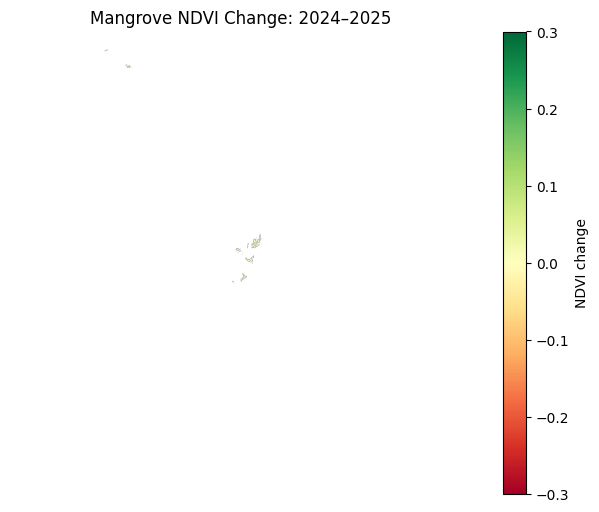

In [ ]:
mangrove_change_map = np.where(
    mangrove_pixels,
    ndvi_change,
    np.nan
)

plt.figure(figsize=(8, 6))

plt.imshow(
    mangrove_change_map,
    cmap="RdYlGn",
    vmin=-0.3,
    vmax=0.3
)

plt.colorbar(label="NDVI change")
plt.title("Mangrove NDVI Change: 2024–2025")
plt.axis("off")
plt.show()

In [ ]:
import json
from google.colab import files

summary = {
    "study_area": "UAE mangrove site",
    "baseline_period": "February–March 2024",
    "comparison_period": "February–March 2025",
    "gmw_mangrove_pixels": int(len(mangrove_ndvi)),
    "median_ndvi": round(float(median_ndvi), 4),
    "robust_health_score": round(float(robust_health_score), 1),
    "mean_ndvi_change": round(float(mean_change), 4),
    "possible_decrease_percent": round(float(decreased.mean() * 100), 2),
    "stable_percent": round(float(stable.mean() * 100), 2),
    "possible_increase_percent": round(float(increased.mean() * 100), 2)
}

with open("mangrove_poc_summary.json", "w") as file:
    json.dump(summary, file, indent=2)

print(json.dumps(summary, indent=2))

{
  "study_area": "UAE mangrove site",
  "baseline_period": "February\u2013March 2024",
  "comparison_period": "February\u2013March 2025",
  "gmw_mangrove_pixels": 535,
  "median_ndvi": 0.0039,
  "robust_health_score": 27.6,
  "mean_ndvi_change": 0.0066,
  "possible_decrease_percent": 0.37,
  "stable_percent": 99.63,
  "possible_increase_percent": 0.0
}


In [ ]:
files.download("mangrove_poc_summary.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Sentinel NDVI shape:", ndvi_later.shape)
print("GMW mosaic shape:", mosaic.shape)

print("GMW values:", np.unique(mosaic))
print("GMW transform:", transform)

signed_later = planetary_computer.sign(later_s2)

with rasterio.open(signed_later.assets["B04"].href) as src:
    print("Sentinel CRS:", src.crs)
    print("Sentinel bounds:", src.bounds)
    print("Sentinel size:", src.width, src.height)

Sentinel NDVI shape: (1200, 1200)
GMW mosaic shape: (1, 18000, 27000)
GMW values: [0 1]
GMW transform: | 0.00, 0.00, 51.00|
| 0.00,-0.00, 27.00|
| 0.00, 0.00, 1.00|
Sentinel CRS: EPSG:32616
Sentinel bounds: BoundingBox(left=300000.0, bottom=1390200.0, right=409800.0, top=1500000.0)
Sentinel size: 10980 10980


In [5]:
import rasterio
from rasterio.warp import transform_bounds

# 1. Inspect the Sentinel-2 metadata and projections
signed_later = planetary_computer.sign(later_s2)
with rasterio.open(signed_later.assets["B04"].href) as src:
    s2_crs = src.crs
    s2_bounds = src.bounds
    s2_width, s2_height = src.width, src.height

print("=== Sentinel-2 Scene Info ===")
print("STAC Item ID:", later_s2.id)
print("STAC BBox (Geo):", later_s2.bbox)
print("Raster CRS:", s2_crs)
print("Raster Bounds in Native CRS:", s2_bounds)
print("Raster Size:", s2_width, s2_height)

# Project the STAC Geo BBox into the Raster Native CRS to see if they align
projected_stac_bbox = transform_bounds("EPSG:4326", s2_crs, *later_s2.bbox)
print("Projected STAC BBox in Native CRS:", projected_stac_bbox)

print("\n=== GMW Mosaic Info ===")
print("GMW Mosaic shape:", mosaic.shape)
print("GMW transform:", transform)
print("GMW CRS: EPSG:4326")


NameError: name 'planetary_computer' is not defined

In [9]:
import matplotlib.pyplot as plt
import shapely.geometry
import geopandas as gpd

# 1. Compute GMW Mosaic Bounds using transform and mosaic shape
gmw_west = transform.c
gmw_top = transform.f
gmw_east = gmw_west + transform.a * mosaic.shape[2]
gmw_bottom = gmw_top + transform.e * mosaic.shape[1]

gmw_geom = shapely.geometry.box(gmw_west, gmw_bottom, gmw_east, gmw_top)
gdf_gmw = gpd.GeoDataFrame({"geometry": [gmw_geom]}, crs="EPSG:4326")

# 2. Sentinel-2 Scene Footprint from the STAC metadata
s2_bbox = later_s2.bbox
s2_geom = shapely.geometry.box(*s2_bbox)
gdf_s2 = gpd.GeoDataFrame({"geometry": [s2_geom]}, crs="EPSG:4326")

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))

# Plot GMW coverage area
gdf_gmw.plot(ax=ax, facecolor="none", edgecolor="green", linewidth=2, label="GMW UAE Mosaic")
# Plot Sentinel-2 footprint
gdf_s2.plot(ax=ax, facecolor="blue", alpha=0.3, edgecolor="blue", linewidth=2, label="Sentinel-2 Footprint")

plt.title("GMW Mosaic and Sentinel-2 Footprint Comparison (Geographic EPSG:4326)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("GMW Mosaic Extent:", [gmw_west, gmw_bottom, gmw_east, gmw_top])
print("Sentinel-2 Footprint BBox:", s2_bbox)

NameError: name 'later_s2' is not defined

In [ ]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

uae_bbox = [51.0, 22.0, 56.5, 26.5]

def get_uae_scene(start_date, end_date):
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=uae_bbox,
        datetime=f"{start_date}/{end_date}",
        query={"eo:cloud_cover": {"lt": 20}}
    )

    items = list(search.get_items())

    if len(items) == 0:
        raise ValueError("No UAE Sentinel-2 scenes found.")

    items = sorted(
        items,
        key=lambda item: item.properties.get("eo:cloud_cover", 100)
    )

    item = items[0]

    print("Selected scene:", item.id)
    print("Scene bbox:", item.bbox)
    print("Cloud cover:", item.properties.get("eo:cloud_cover"))

    return item

baseline_s2 = get_uae_scene(
    "2024-02-01",
    "2024-03-10"
)

later_s2 = get_uae_scene(
    "2025-02-01",
    "2025-03-10"
)

/usr/local/lib/python3.13/dist-packages/pystac_client/item_search.py:925: FutureWarning: get_items() is deprecated, use items() instead
  warnings.warn(


Selected scene: S2B_MSIL2A_20240306T065739_R063_T39RWJ_20240306T110954
Scene bbox: [51.93086456, 25.22439454, 52.0960904, 25.90637353]
Cloud cover: 0.0
Selected scene: S2C_MSIL2A_20250306T065811_R063_T40QBK_20250306T124721
Scene bbox: [54.0822841, 22.119338, 54.2106047, 22.5824286]
Cloud cover: 0.0


In [ ]:
def get_same_tile_scene(start_date, end_date, tile_name):
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=uae_bbox,
        datetime=f"{start_date}/{end_date}",
        query={
            "eo:cloud_cover": {"lt": 20},
            "s2:mgrs_tile": {"eq": tile_name}
        }
    )

    items = list(search.get_items())

    if len(items) == 0:
        raise ValueError("No matching scene found.")

    items = sorted(
        items,
        key=lambda item: item.properties.get("eo:cloud_cover", 100)
    )

    item = items[0]

    print("Scene:", item.id)
    print("BBox:", item.bbox)
    print("Cloud cover:", item.properties.get("eo:cloud_cover"))

    return item

baseline_s2 = get_same_tile_scene(
    "2024-02-01",
    "2024-03-10",
    "39RWJ"
)

later_s2 = get_same_tile_scene(
    "2025-02-01",
    "2025-03-10",
    "39RWJ"
)

Scene: S2B_MSIL2A_20240306T065739_R063_T39RWJ_20240306T110954
BBox: [51.93086456, 25.22439454, 52.0960904, 25.90637353]
Cloud cover: 0.0
Scene: S2C_MSIL2A_20250204T070131_R063_T39RWJ_20250204T101810
BBox: [51.9071337, 25.2243945, 52.097045, 26.010674]
Cloud cover: 0.000262


In [ ]:
print("Sentinel item ID:", later_s2.id)
print("Sentinel collection:", later_s2.collection_id)
print("Sentinel bbox:", later_s2.bbox)
print("Sentinel EPSG:", later_s2.properties.get("proj:epsg"))

Sentinel item ID: S2C_MSIL2A_20250219T161341_R140_T16PCV_20250219T193154
Sentinel collection: sentinel-2-l2a
Sentinel bbox: [-88.8482723, 12.5692422, -87.8303669, 13.5670592]
Sentinel EPSG: None


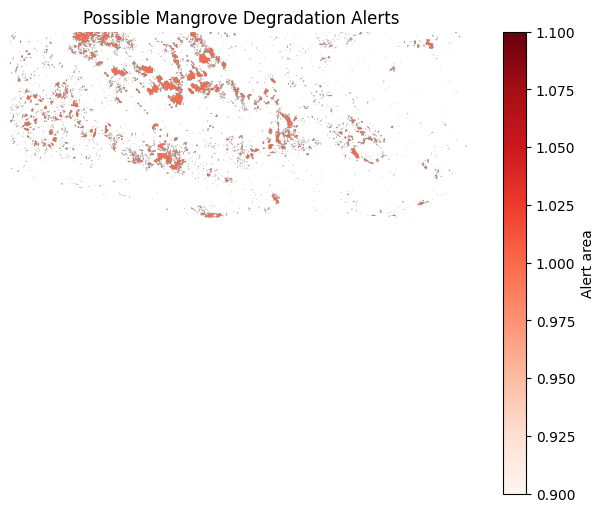

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

degradation = np.where(ndvi_change < -0.10, 1, np.nan)

fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(degradation, cmap="Reds")
ax.set_title("Possible Mangrove Degradation Alerts")
ax.axis("off")

fig.colorbar(image, ax=ax, label="Alert area")

fig.savefig(
    "possible_mangrove_degradation_alerts.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
plt.savefig(
    "possible_mangrove_degradation_alerts.png",
    dpi=200,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
import requests
import zipfile
import io
import os

record_url = "https://zenodo.org/api/records/6894273"
record = requests.get(record_url).json()

file_info = next(
    f for f in record["files"]
    if f["key"] == "gmw_v3_2020_gtiff.zip"
)

download_url = file_info["links"]["self"]

print("Downloading GMW 2020 reference map...")

response = requests.get(download_url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("gmw_2020")

print("GMW 2020 map downloaded and extracted.")
print(os.listdir("gmw_2020"))

GMW 2020 map downloaded and extracted.
['gmw_v3_2020']


In [ ]:
import glob
import rasterio

gmw_files = glob.glob(
    "gmw_2020/**/*.tif",
    recursive=True
)

print("GMW files found:")
for file in gmw_files:
    print(file)

gmw_path = gmw_files[0]

with rasterio.open(gmw_path) as src:
    print("\nProjection:", src.crs)
    print("Map size:", src.width, "x", src.height)
    print("Bands:", src.count)

GMW files found:
gmw_2020/gmw_v3_2020/GMW_N19W104_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_S05E053_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_S11E133_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_S22W043_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N09W060_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N22E112_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N12E093_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_S15E127_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N06E121_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_S04E136_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_S34E173_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N10E104_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N02W050_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N16W017_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N20E106_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_S08E013_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N06W001_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N21E071_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N12E102_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N22E092_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_S01E100_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N12E120_2020_

UAE tiles found:
gmw_2020/gmw_v3_2020/GMW_N26E051_2020_v3.tif
gmw_2020/gmw_v3_2020/GMW_N26E056_2020_v3.tif


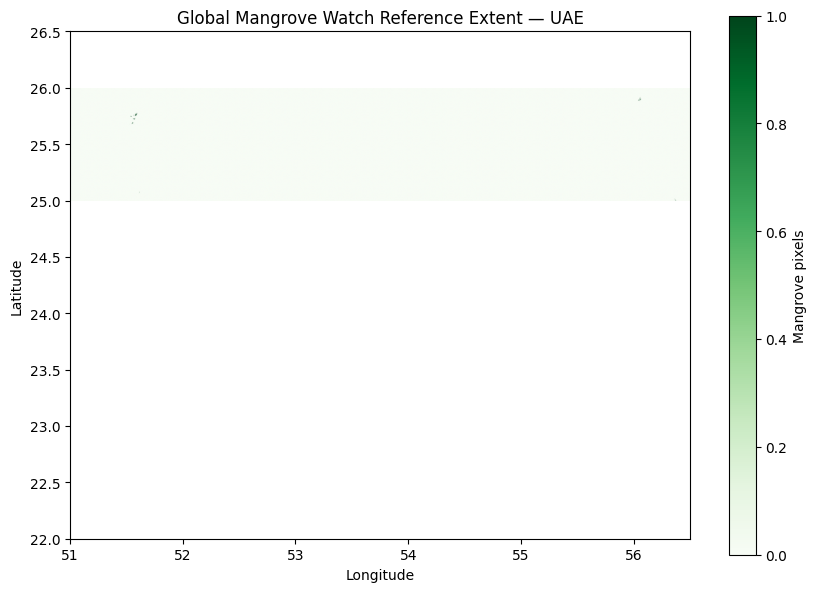

In [ ]:
import glob
import rasterio
import matplotlib.pyplot as plt
from rasterio.merge import merge

# UAE area: approximately 22–26°N, 51–56°E
tile_codes = [
    "N22E051",
    "N22E056",
    "N26E051",
    "N26E056"
]

all_gmw_files = glob.glob(
    "gmw_2020/**/*.tif",
    recursive=True
)

uae_files = [
    file for file in all_gmw_files
    if any(code in file for code in tile_codes)
]

print("UAE tiles found:")
for file in uae_files:
    print(file)

# Combine the UAE tiles
sources = [rasterio.open(file) for file in uae_files]

mosaic, transform = merge(sources)

for source in sources:
    source.close()

# Reduce display size
display_map = mosaic[0][::5, ::5]

left = transform.c
top = transform.f
right = left + transform.a * mosaic.shape[2]
bottom = top + transform.e * mosaic.shape[1]

plt.figure(figsize=(10, 7))

plt.imshow(
    display_map,
    cmap="Greens",
    extent=[left, right, bottom, top],
    origin="upper"
)

plt.xlim(51, 56.5)
plt.ylim(22, 26.5)

plt.title("Global Mangrove Watch Reference Extent — UAE")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label="Mangrove pixels")
plt.show()

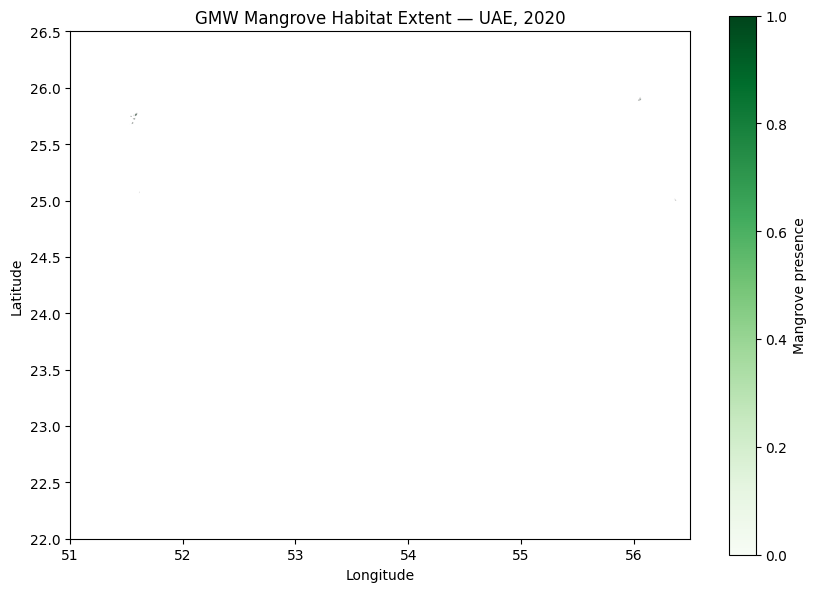

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Use the combined GMW map
gmw_binary = mosaic[0][::5, ::5]

# Hide all non-mangrove pixels
gmw_visible = np.ma.masked_where(gmw_binary == 0, gmw_binary)

plt.figure(figsize=(10, 7))

plt.imshow(
    gmw_visible,
    cmap="Greens",
    vmin=0,
    vmax=1,
    extent=[left, right, bottom, top],
    origin="upper"
)

plt.xlim(51, 56.5)
plt.ylim(22, 26.5)

plt.title("GMW Mangrove Habitat Extent — UAE, 2020")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label="Mangrove presence")
plt.show()

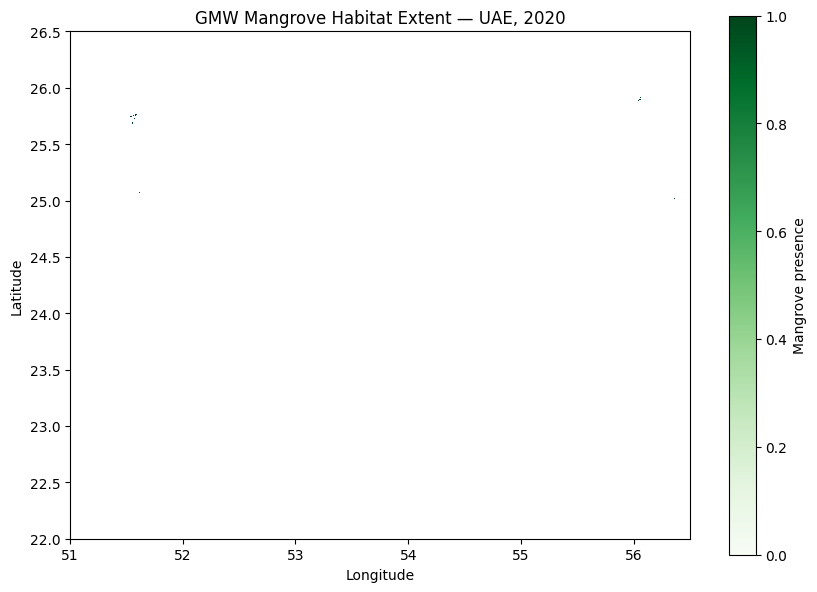

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

full_map = mosaic[0]

# Preserve mangrove pixels while reducing image size
factor = 5

height = (full_map.shape[0] // factor) * factor
width = (full_map.shape[1] // factor) * factor

trimmed = full_map[:height, :width]

display_map = trimmed.reshape(
    height // factor,
    factor,
    width // factor,
    factor
).max(axis=(1, 3))

visible_map = np.ma.masked_where(display_map == 0, display_map)

plt.figure(figsize=(10, 7))

plt.imshow(
    visible_map,
    cmap="Greens",
    vmin=0,
    vmax=1,
    extent=[left, right, bottom, top],
    origin="upper",
    interpolation="nearest"
)

plt.xlim(51, 56.5)
plt.ylim(22, 26.5)

plt.title("GMW Mangrove Habitat Extent — UAE, 2020")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label="Mangrove presence")
plt.show()

In [ ]:
import glob
import rasterio

uae_bbox = (51, 22, 56.5, 26.5)

all_gmw_files = glob.glob(
    "gmw_2020/**/*.tif",
    recursive=True
)

uae_files = []

for file in all_gmw_files:
    with rasterio.open(file) as src:
        bounds = src.bounds

        overlaps_uae = (
            bounds.right >= uae_bbox[0]
            and bounds.left <= uae_bbox[2]
            and bounds.top >= uae_bbox[1]
            and bounds.bottom <= uae_bbox[3]
        )

        if overlaps_uae:
            uae_files.append(file)
            print(file, "→", bounds)

print("\nTotal UAE tiles:", len(uae_files))

gmw_2020/gmw_v3_2020/GMW_N27E055_2020_v3.tif → BoundingBox(left=55.0, bottom=26.000000000001, right=55.999999999999, top=27.0)
gmw_2020/gmw_v3_2020/GMW_N26E051_2020_v3.tif → BoundingBox(left=51.0, bottom=25.000000000001, right=51.999999999999, top=26.0)
gmw_2020/gmw_v3_2020/GMW_N27E056_2020_v3.tif → BoundingBox(left=56.0, bottom=26.000000000001, right=56.999999999999, top=27.0)
gmw_2020/gmw_v3_2020/GMW_N25E056_2020_v3.tif → BoundingBox(left=56.0, bottom=24.000000000001, right=56.999999999999, top=25.0)
gmw_2020/gmw_v3_2020/GMW_N26E056_2020_v3.tif → BoundingBox(left=56.0, bottom=25.000000000001, right=56.999999999999, top=26.0)
gmw_2020/gmw_v3_2020/GMW_N24E052_2020_v3.tif → BoundingBox(left=52.0, bottom=23.000000000001, right=52.999999999999, top=24.0)
gmw_2020/gmw_v3_2020/GMW_N26E055_2020_v3.tif → BoundingBox(left=55.0, bottom=25.000000000001, right=55.999999999999, top=26.0)
gmw_2020/gmw_v3_2020/GMW_N25E054_2020_v3.tif → BoundingBox(left=54.0, bottom=24.000000000001, right=54.99999999

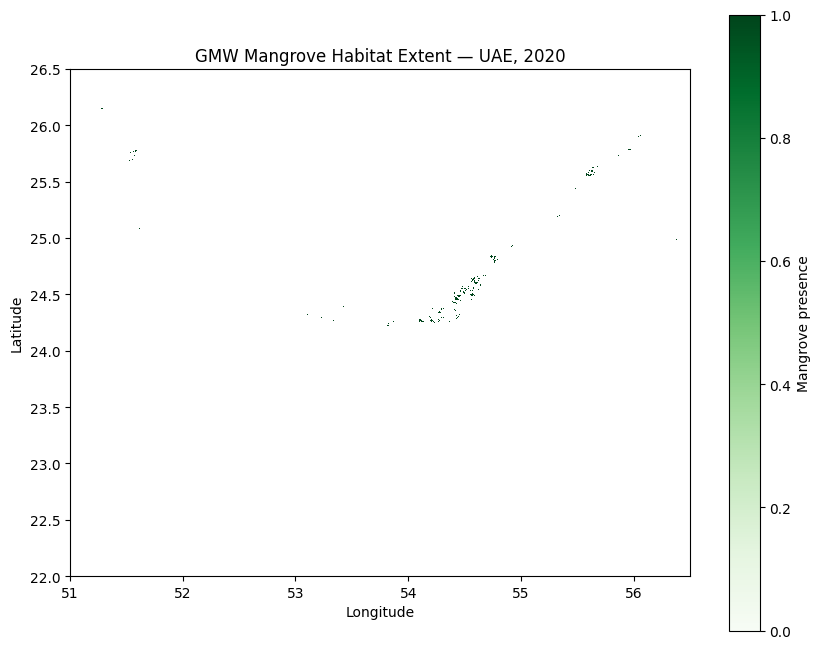

In [ ]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from rasterio.merge import merge

# Merge all UAE tiles
sources = [rasterio.open(file) for file in uae_files]

mosaic, transform = merge(sources)

for source in sources:
    source.close()

full_map = mosaic[0]

# Preserve mangrove pixels while reducing display size
factor = 5

height = (full_map.shape[0] // factor) * factor
width = (full_map.shape[1] // factor) * factor

trimmed = full_map[:height, :width]

display_map = trimmed.reshape(
    height // factor,
    factor,
    width // factor,
    factor
).max(axis=(1, 3))

visible_map = np.ma.masked_where(display_map == 0, display_map)

left = transform.c
top = transform.f
right = left + transform.a * full_map.shape[1]
bottom = top + transform.e * full_map.shape[0]

plt.figure(figsize=(10, 8))

plt.imshow(
    visible_map,
    cmap="Greens",
    vmin=0,
    vmax=1,
    extent=[left, right, bottom, top],
    origin="upper",
    interpolation="nearest"
)

plt.xlim(51, 56.5)
plt.ylim(22, 26.5)

plt.title("GMW Mangrove Habitat Extent — UAE, 2020")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label="Mangrove presence")
plt.show()

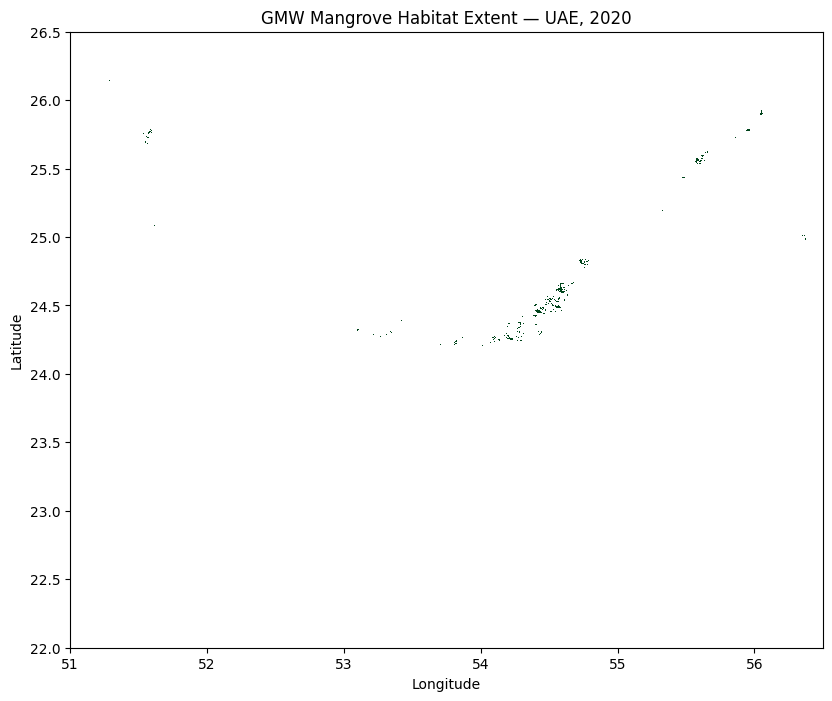

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(
    visible_map,
    cmap="Greens",
    vmin=0,
    vmax=1,
    extent=[left, right, bottom, top],
    origin="upper",
    interpolation="nearest"
)

ax.set_xlim(51, 56.5)
ax.set_ylim(22, 26.5)

ax.set_title("GMW Mangrove Habitat Extent — UAE, 2020")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

fig.savefig(
    "gmw_uae_reference.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

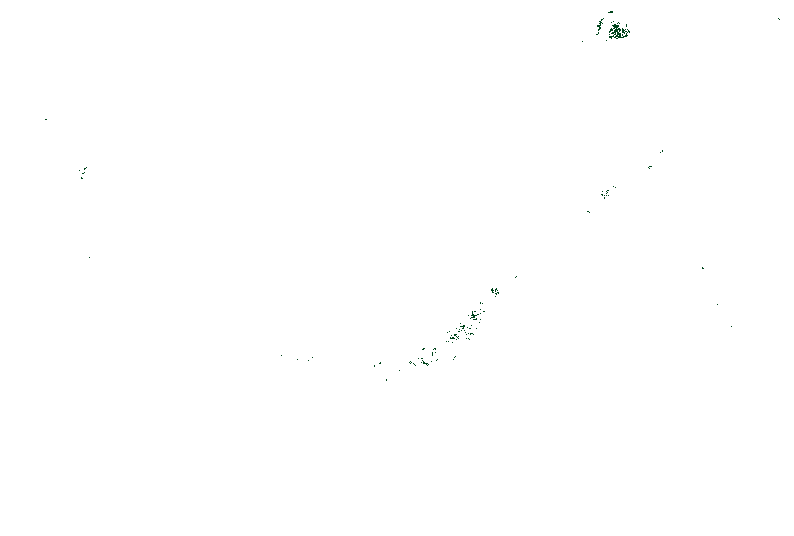

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(
    visible_map,
    cmap="Greens",
    vmin=0,
    vmax=1,
    extent=[left, right, bottom, top],
    origin="upper",
    interpolation="nearest"
)

ax.set_axis_off()

fig.savefig(
    "gmw_uae_overlay.png",
    dpi=200,
    bbox_inches="tight",
    transparent=True,
    pad_inches=0
)

plt.show()

In [ ]:
import json
from affine import Affine
from rasterio.features import shapes

# Convert the reduced GMW raster into geographic polygons
coarse_transform = transform * Affine.scale(factor, factor)

features = []

for geometry, value in shapes(
    display_map.astype("uint8"),
    mask=(display_map == 1),
    transform=coarse_transform
):
    features.append({
        "type": "Feature",
        "geometry": geometry,
        "properties": {
            "layer": "GMW Mangrove Habitat Extent",
            "year": 2020,
            "class": "Mangrove"
        }
    })

gmw_geojson = {
    "type": "FeatureCollection",
    "features": features
}

with open("gmw_uae_extent.geojson", "w") as file:
    json.dump(gmw_geojson, file)

print("Clickable GMW vector layer created.")
print("Number of polygons:", len(features))

Clickable GMW vector layer created.
Number of polygons: 791


In [13]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd

from pystac_client import Client
import planetary_computer

# Connect to Microsoft Planetary Computer
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

# GCC mangrove study sites
gcc_sites = {
    "Saudi Arabia": (38.5, 16.5, 43.5, 20.5),
    "Bahrain": (50.3, 25.7, 50.8, 26.4),
    "Qatar": (50.6, 24.4, 51.7, 26.2),
    "United Arab Emirates": (51.5, 22.5, 56.5, 26.5),
    "Oman": (56.5, 16.5, 60.0, 26.5),
    "Kuwait": (46.5, 28.4, 48.5, 30.2)
}

# Analysis dates
baseline_period = "2024-02-01/2024-03-10"
later_period = "2025-02-01/2025-03-10"

print("Sentinel-2 catalog connected.")
print("GCC countries:", len(gcc_sites))
print("Baseline:", baseline_period)
print("Later:", later_period)

Sentinel-2 catalog connected.
GCC countries: 6
Baseline: 2024-02-01/2024-03-10
Later: 2025-02-01/2025-03-10


In [14]:
def find_best_scene(site_name, bbox, date_range):
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=date_range,
        query={
            "eo:cloud_cover": {"lt": 20}
        }
    )

    items = list(search.item_collection())

    if not items:
        return None

    items = sorted(
        items,
        key=lambda item: item.properties.get(
            "eo:cloud_cover",
            100
        )
    )

    scene = items[0]

    return {
        "country": site_name,
        "scene_id": scene.id,
        "cloud_cover": scene.properties.get(
            "eo:cloud_cover",
            None
        ),
        "date": scene.datetime.strftime("%Y-%m-%d"),
        "bbox": scene.bbox,
        "item": scene
    }


baseline_scenes = []
later_scenes = []

for country, bbox in gcc_sites.items():
    baseline_scene = find_best_scene(
        country,
        bbox,
        baseline_period
    )

    later_scene = find_best_scene(
        country,
        bbox,
        later_period
    )

    if baseline_scene:
        baseline_scenes.append(baseline_scene)

    if later_scene:
        later_scenes.append(later_scene)


print("Baseline scenes found:", len(baseline_scenes))
print("Later scenes found:", len(later_scenes))

print("\nBaseline scenes:")
for scene in baseline_scenes:
    print(
        scene["country"],
        scene["date"],
        scene["cloud_cover"]
    )

print("\nLater scenes:")
for scene in later_scenes:
    print(
        scene["country"],
        scene["date"],
        scene["cloud_cover"]
    )

Baseline scenes found: 6
Later scenes found: 6

Baseline scenes:
Saudi Arabia 2024-03-10 0.0
Bahrain 2024-03-09 0.065673
Qatar 2024-02-23 9.3e-05
United Arab Emirates 2024-03-06 0.0
Oman 2024-02-24 0.0
Kuwait 2024-02-19 3e-06

Later scenes:
Saudi Arabia 2025-03-03 0.0
Bahrain 2025-02-02 0.061227
Qatar 2025-02-02 0.00858
United Arab Emirates 2025-03-06 0.0
Oman 2025-03-10 0.0
Kuwait 2025-02-08 0.000411


In [27]:
import rasterio
from rasterio.windows import from_bounds


def load_band_for_site(
    scene_info,
    band_name,
    site_bbox,
    output_size=1000
):
    scene = scene_info["item"]
    band_url = scene.assets[band_name].href

    with rasterio.open(band_url) as src:
        # Convert the GCC bbox into the Sentinel image CRS
        bbox = rasterio.warp.transform_bounds(
            "EPSG:4326",
            src.crs,
            *site_bbox,
            densify_pts=21
        )

        window = from_bounds(
            *bbox,
            transform=src.transform
        )

        band = src.read(
            1,
            window=window,
            out_shape=(output_size, output_size),
            boundless=True,
            fill_value=np.nan,
            out_dtype="float32"
        )

        transform = src.window_transform(window)
        crs = src.crs

    return band, transform, crs


print("Corrected consistent-grid loader is ready.")

Corrected consistent-grid loader is ready.


In [34]:
country = "United Arab Emirates"
site_bbox = gcc_sites[country]

red_baseline, baseline_transform, baseline_crs = (
    load_band_for_site(
        uae_baseline_scene,
        "B04",
        site_bbox
    )
)

nir_baseline, _, _ = load_band_for_site(
    uae_baseline_scene,
    "B08",
    site_bbox
)

red_later, later_transform, later_crs = (
    load_band_for_site(
        uae_later_scene,
        "B04",
        site_bbox
    )
)

nir_later, _, _ = load_band_for_site(
    uae_later_scene,
    "B08",
    site_bbox
)

print("Country:", country)
print("Baseline red shape:", red_baseline.shape)
print("Baseline NIR shape:", nir_baseline.shape)
print("Later red shape:", red_later.shape)
print("Later NIR shape:", nir_later.shape)
print("Baseline CRS:", baseline_crs)
print("Later CRS:", later_crs)

Country: United Arab Emirates
Baseline red shape: (1000, 1000)
Baseline NIR shape: (1000, 1000)
Later red shape: (1000, 1000)
Later NIR shape: (1000, 1000)
Baseline CRS: EPSG:32640
Later CRS: EPSG:32640


In [37]:
def calculate_ndvi(red, nir):
    red = red.astype("float32")
    nir = nir.astype("float32")

    with np.errstate(
        divide="ignore",
        invalid="ignore"
    ):
        ndvi = (nir - red) / (nir + red)

    ndvi[~np.isfinite(ndvi)] = np.nan

    return ndvi


ndvi_baseline = calculate_ndvi(
    red_baseline,
    nir_baseline
)

ndvi_later = calculate_ndvi(
    red_later,
    nir_later
)

ndvi_change = ndvi_later - ndvi_baseline

valid_pixels = (
    np.isfinite(ndvi_baseline)
    & np.isfinite(ndvi_later)
)

print("Valid pixels:", int(valid_pixels.sum()))

print(
    "Baseline median NDVI:",
    float(np.nanmedian(ndvi_baseline))
)

print(
    "Later median NDVI:",
    float(np.nanmedian(ndvi_later))
)

print(
    "Median NDVI change:",
    float(np.nanmedian(ndvi_change))
)

print(
    "Strong decrease:",
    f"{100 * np.mean(ndvi_change[valid_pixels] < -0.10):.2f}%"
)

print(
    "Strong increase:",
    f"{100 * np.mean(ndvi_change[valid_pixels] > 0.10):.2f}%"
)

Valid pixels: 21023
Baseline median NDVI: -0.01283226441591978
Later median NDVI: -0.015442208386957645
Median NDVI change: 0.0054036956280469894
Strong decrease: 3.55%
Strong increase: 6.24%


In [38]:
print(
    "Baseline finite pixels:",
    int(np.isfinite(ndvi_baseline).sum())
)

print(
    "Later finite pixels:",
    int(np.isfinite(ndvi_later).sum())
)

print(
    "Baseline transform:",
    baseline_transform
)

print(
    "Later transform:",
    later_transform
)

print(
    "Baseline CRS:",
    baseline_crs
)

print(
    "Later CRS:",
    later_crs
)

Baseline finite pixels: 37539
Later finite pixels: 34987
Baseline transform: | 10.00, 0.00,-66322.17|
| 0.00,-10.00, 2942829.91|
| 0.00, 0.00, 1.00|
Later transform: | 10.00, 0.00,-66322.17|
| 0.00,-10.00, 2942829.91|
| 0.00, 0.00, 1.00|
Baseline CRS: EPSG:32640
Later CRS: EPSG:32640


In [39]:
def find_scene_for_tile(
    tile_name,
    date_range,
    bbox
):
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=date_range,
        query={
            "eo:cloud_cover": {"lt": 20},
            "s2:mgrs_tile": {"eq": tile_name}
        }
    )

    items = list(search.item_collection())

    if not items:
        raise ValueError(
            f"No scene found for tile {tile_name}"
        )

    items = sorted(
        items,
        key=lambda item: item.properties.get(
            "eo:cloud_cover",
            100
        )
    )

    item = items[0]

    return {
        "country": "United Arab Emirates",
        "scene_id": item.id,
        "cloud_cover": item.properties.get(
            "eo:cloud_cover",
            None
        ),
        "date": item.datetime.strftime("%Y-%m-%d"),
        "bbox": item.bbox,
        "item": item
    }


uae_bbox = gcc_sites["United Arab Emirates"]

uae_baseline_scene = find_scene_for_tile(
    "40RBN",
    baseline_period,
    uae_bbox
)

uae_later_scene = find_scene_for_tile(
    "40RBN",
    later_period,
    uae_bbox
)

print("Baseline tile:", uae_baseline_scene["item"].properties["s2:mgrs_tile"])
print("Baseline date:", uae_baseline_scene["date"])
print("Later tile:", uae_later_scene["item"].properties["s2:mgrs_tile"])
print("Later date:", uae_later_scene["date"])

Baseline tile: 40RBN
Baseline date: 2024-02-22
Later tile: 40RBN
Later date: 2025-02-04


In [41]:
def find_common_tile_scenes(
    country,
    bbox,
    baseline_period,
    later_period
):
    baseline_search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=baseline_period,
        query={
            "eo:cloud_cover": {"lt": 20}
        }
    )

    later_search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=later_period,
        query={
            "eo:cloud_cover": {"lt": 20}
        }
    )

    baseline_items = list(
        baseline_search.item_collection()
    )

    later_items = list(
        later_search.item_collection()
    )

    baseline_by_tile = {}
    later_by_tile = {}

    for item in baseline_items:
        tile = item.properties.get("s2:mgrs_tile")

        if tile:
            baseline_by_tile.setdefault(
                tile,
                []
            ).append(item)

    for item in later_items:
        tile = item.properties.get("s2:mgrs_tile")

        if tile:
            later_by_tile.setdefault(
                tile,
                []
            ).append(item)

    common_tiles = sorted(
        set(baseline_by_tile)
        & set(later_by_tile)
    )

    if not common_tiles:
        return None

    tile = common_tiles[0]

    baseline_item = sorted(
        baseline_by_tile[tile],
        key=lambda item: item.properties.get(
            "eo:cloud_cover",
            100
        )
    )[0]

    later_item = sorted(
        later_by_tile[tile],
        key=lambda item: item.properties.get(
            "eo:cloud_cover",
            100
        )
    )[0]

    return {
        "country": country,
        "tile": tile,
        "baseline": baseline_item,
        "later": later_item
    }


gcc_scene_pairs = {}

for country, bbox in gcc_sites.items():
    pair = find_common_tile_scenes(
        country,
        bbox,
        baseline_period,
        later_period
    )

    if pair:
        gcc_scene_pairs[country] = pair

        print(
            country,
            "-> tile:",
            pair["tile"],
            "| baseline:",
            pair["baseline"].datetime.strftime("%Y-%m-%d"),
            "| later:",
            pair["later"].datetime.strftime("%Y-%m-%d")
        )
    else:
        print(
            country,
            "-> no common Sentinel-2 tile found"
        )

print(
    "\nCountries with matching scenes:",
    len(gcc_scene_pairs)
)

Saudi Arabia -> tile: 37QDA | baseline: 2024-03-01 | later: 2025-02-04
Bahrain -> tile: 39RVJ | baseline: 2024-02-08 | later: 2025-02-02
Qatar -> tile: 39QVG | baseline: 2024-02-23 | later: 2025-02-02
United Arab Emirates -> tile: 39QWE | baseline: 2024-02-28 | later: 2025-02-22
Oman -> tile: 40QDD | baseline: 2024-02-09 | later: 2025-02-23
Kuwait -> tile: 38RPS | baseline: 2024-02-09 | later: 2025-02-08

Countries with matching scenes: 6


In [42]:
gcc_results = []

for country, pair in gcc_scene_pairs.items():

    site_bbox = gcc_sites[country]

    baseline_info = {
        "item": pair["baseline"]
    }

    later_info = {
        "item": pair["later"]
    }

    red_baseline, _, _ = load_band_for_site(
        baseline_info,
        "B04",
        site_bbox,
        output_size=500
    )

    nir_baseline, _, _ = load_band_for_site(
        baseline_info,
        "B08",
        site_bbox,
        output_size=500
    )

    red_later, _, _ = load_band_for_site(
        later_info,
        "B04",
        site_bbox,
        output_size=500
    )

    nir_later, _, _ = load_band_for_site(
        later_info,
        "B08",
        site_bbox,
        output_size=500
    )

    ndvi_baseline_country = calculate_ndvi(
        red_baseline,
        nir_baseline
    )

    ndvi_later_country = calculate_ndvi(
        red_later,
        nir_later
    )

    change_country = (
        ndvi_later_country
        - ndvi_baseline_country
    )

    valid = (
        np.isfinite(ndvi_baseline_country)
        & np.isfinite(ndvi_later_country)
    )

    if int(valid.sum()) == 0:
        print(country, "-> no overlapping valid pixels")
        continue

    baseline_median = float(
        np.nanmedian(
            ndvi_baseline_country[valid]
        )
    )

    later_median = float(
        np.nanmedian(
            ndvi_later_country[valid]
        )
    )

    change_median = float(
        np.nanmedian(
            change_country[valid]
        )
    )

    decrease_percent = float(
        100 * np.mean(
            change_country[valid] < -0.10
        )
    )

    increase_percent = float(
        100 * np.mean(
            change_country[valid] > 0.10
        )
    )

    # Convert later NDVI into a 0–100 health score
    health_score = float(
        np.clip(
            (later_median - 0.10) / 0.60 * 100,
            0,
            100
        )
    )

    if health_score >= 70:
        status = "Healthy"
    elif health_score >= 40:
        status = "Moderate"
    else:
        status = "Stressed"

    gcc_results.append({
        "country": country,
        "tile": pair["tile"],
        "baseline_date": pair["baseline"].datetime.strftime(
            "%Y-%m-%d"
        ),
        "later_date": pair["later"].datetime.strftime(
            "%Y-%m-%d"
        ),
        "baseline_ndvi": baseline_median,
        "later_ndvi": later_median,
        "ndvi_change": change_median,
        "health_score": health_score,
        "decrease_percent": decrease_percent,
        "increase_percent": increase_percent,
        "status": status
    })

    print(
        country,
        "| health:",
        round(health_score, 1),
        "| change:",
        round(change_median, 4),
        "| status:",
        status
    )

print(
    "\nCountries successfully analyzed:",
    len(gcc_results)
)

Saudi Arabia | health: 0.0 | change: 0.0143 | status: Stressed
Bahrain | health: 0.0 | change: 0.0048 | status: Stressed
Qatar | health: 0.0 | change: 0.012 | status: Stressed
United Arab Emirates | health: 0.0 | change: 0.0007 | status: Stressed
Oman | health: 0.0 | change: -0.007 | status: Stressed
Kuwait | health: 0.0 | change: -0.012 | status: Stressed

Countries successfully analyzed: 6


In [43]:
import geopandas as gpd
from shapely.geometry import shape


# Load the corrected GCC mangrove GeoJSON
with open(
    "gcc_mangrove_analysis_points.geojson",
    "r",
    encoding="utf-8"
) as file:
    gcc_geojson = json.load(file)


mangrove_rows = []

for feature in gcc_geojson["features"]:
    coordinates = feature["geometry"]["coordinates"]
    longitude = float(coordinates[0])
    latitude = float(coordinates[1])

    mangrove_rows.append({
        "longitude": longitude,
        "latitude": latitude
    })


mangrove_points_df = pd.DataFrame(
    mangrove_rows
)

print(
    "Mangrove points loaded:",
    len(mangrove_points_df)
)

print(
    mangrove_points_df.head()
)

Mangrove points loaded: 475
   longitude   latitude
0  49.244556  27.413222
1  49.204556  27.382111
2  49.315667  27.288778
3  49.337889  27.239889
4  49.333444  27.208778


In [7]:
# Load global coastline
coastline_url = (
    "https://raw.githubusercontent.com/"
    "nvkelso/natural-earth-vector/master/geojson/"
    "ne_110m_coastline.geojson"
)

coastline = gpd.read_file(coastline_url)

# Combine all coastline segments
coastline_geometry = coastline.geometry.unary_union

# Create point geometries
point_geometry = gpd.GeoSeries(
    gpd.points_from_xy(
        mangrove_points_df["longitude"],
        mangrove_points_df["latitude"]
    ),
    crs="EPSG:4326"
)

# Approximate coastal filter:
# keep points within about 0.5 degrees of coastline
distance_to_coast = point_geometry.distance(
    coastline_geometry
)

coastal_points_df = mangrove_points_df[
    distance_to_coast <= 0.5
].copy()

print(
    "Original sampled points:",
    len(mangrove_points_df)
)

print(
    "Coastal mangrove reference points:",
    len(coastal_points_df)
)

NameError: name 'gpd' is not defined

In [6]:
countries_url = (
    "https://raw.githubusercontent.com/"
    "nvkelso/natural-earth-vector/master/geojson/"
    "ne_110m_admin_0_countries.geojson"
)

world = gpd.read_file(countries_url)

gcc_country_names = [
    "Saudi Arabia",
    "United Arab Emirates",
    "Oman",
    "Qatar",
    "Bahrain",
    "Kuwait"
]

gcc_boundaries = world[
    world["ADMIN"].isin(gcc_country_names)
][["ADMIN", "geometry"]].copy()

gcc_boundaries = gcc_boundaries.rename(
    columns={"ADMIN": "country"}
)

point_geodata = gpd.GeoDataFrame(
    mangrove_points_df.copy(),
    geometry=gpd.points_from_xy(
        mangrove_points_df["longitude"],
        mangrove_points_df["latitude"]
    ),
    crs="EPSG:4326"
)

points_with_country = gpd.sjoin(
    point_geodata,
    gcc_boundaries,
    how="inner",
    predicate="within"
)

print(
    "Points assigned to GCC countries:",
    len(points_with_country)
)

print(
    points_with_country["country"].value_counts()
)


NameError: name 'gpd' is not defined

In [5]:
from pyproj import Transformer
from rasterio.transform import rowcol


point_results = []

for country, country_points in points_with_country.groupby(
    "country"
):
    if country not in gcc_scene_pairs:
        continue

    pair = gcc_scene_pairs[country]
    site_bbox = gcc_sites[country]

    baseline_info = {
        "item": pair["baseline"]
    }

    later_info = {
        "item": pair["later"]
    }

    red_baseline, baseline_transform, baseline_crs = (
        load_band_for_site(
            baseline_info,
            "B04",
            site_bbox,
            output_size=500
        )
    )

    nir_baseline, _, _ = load_band_for_site(
        baseline_info,
        "B08",
        site_bbox,
        output_size=500
    )

    red_later, later_transform, later_crs = (
        load_band_for_site(
            later_info,
            "B04",
            site_bbox,
            output_size=500
        )
    )

    nir_later, _, _ = load_band_for_site(
        later_info,
        "B08",
        site_bbox,
        output_size=500
    )

    ndvi_baseline_country = calculate_ndvi(
        red_baseline,
        nir_baseline
    )

    ndvi_later_country = calculate_ndvi(
        red_later,
        nir_later
    )

    transformer_baseline = Transformer.from_crs(
        "EPSG:4326",
        baseline_crs,
        always_xy=True
    )

    transformer_later = Transformer.from_crs(
        "EPSG:4326",
        later_crs,
        always_xy=True
    )

    for _, point in country_points.iterrows():
        longitude = point["longitude"]
        latitude = point["latitude"]

        x_baseline, y_baseline = (
            transformer_baseline.transform(
                longitude,
                latitude
            )
        )

        x_later, y_later = (
            transformer_later.transform(
                longitude,
                latitude
            )
        )

        row_b, col_b = rowcol(
            baseline_transform,
            x_baseline,
            y_baseline
        )

        row_l, col_l = rowcol(
            later_transform,
            x_later,
            y_later
        )

        if not (
            0 <= row_b < ndvi_baseline_country.shape[0]
            and 0 <= col_b < ndvi_baseline_country.shape[1]
            and 0 <= row_l < ndvi_later_country.shape[0]
            and 0 <= col_l < ndvi_later_country.shape[1]
        ):
            continue

        baseline_ndvi = float(
            ndvi_baseline_country[row_b, col_b]
        )

        later_ndvi = float(
            ndvi_later_country[row_l, col_l]
        )

        if not np.isfinite(baseline_ndvi):
            continue

        if not np.isfinite(later_ndvi):
            continue

        ndvi_change = later_ndvi - baseline_ndvi

        health_score = float(
            np.clip(
                (later_ndvi - 0.10) / 0.60 * 100,
                0,
                100
            )
        )

        if health_score >= 70:
            status = "Healthy"
        elif health_score >= 40:
            status = "Moderate"
        else:
            status = "Stressed"

        point_results.append({
            "country": country,
            "longitude": longitude,
            "latitude": latitude,
            "baseline_ndvi": baseline_ndvi,
            "later_ndvi": later_ndvi,
            "ndvi_change": ndvi_change,
            "health_score": health_score,
            "status": status
        })


point_results_df = pd.DataFrame(point_results)

print(
    "Points with valid Sentinel-2 values:",
    len(point_results_df)
)

print(
    point_results_df["status"].value_counts()
)

print(
    point_results_df.head()
)

NameError: name 'points_with_country' is not defined

In [4]:
# Select one representative reference point per country
representative_sites = (
    points_with_country
    .groupby("country", as_index=False)
    .first()
)

representative_sites = representative_sites[
    [
        "country",
        "longitude",
        "latitude"
    ]
].copy()

print(
    "Representative GCC sites:",
    len(representative_sites)
)

print(representative_sites)

NameError: name 'points_with_country' is not defined

In [3]:
# Calculate coastline distance in meters
point_geometry_m = point_geodata.to_crs("EPSG:3857")
coastline_m = coastline.to_crs("EPSG:3857")

coastline_geometry_m = coastline_m.geometry.union_all()

points_with_country = points_with_country.copy()

points_with_country["coast_distance_m"] = (
    point_geometry_m.loc[
        points_with_country.index
    ].distance(coastline_geometry_m)
)

# Select the closest sampled point to the coast in each country
representative_sites = (
    points_with_country
    .sort_values("coast_distance_m")
    .groupby("country", as_index=False)
    .first()
)

representative_sites = representative_sites[
    [
        "country",
        "longitude",
        "latitude",
        "coast_distance_m"
    ]
]

print(
    "Coastal representative sites:",
    len(representative_sites)
)

print(representative_sites)

NameError: name 'point_geodata' is not defined

In [10]:
import json
import numpy as np


valid_pixels = (
    np.isfinite(ndvi_baseline)
    & np.isfinite(ndvi_later)
)

baseline_values = ndvi_baseline[valid_pixels]
later_values = ndvi_later[valid_pixels]
change_values = ndvi_change[valid_pixels]

ndvi_summary = {
    "region": "United Arab Emirates",
    "baseline_date": "2024-02-22",
    "later_date": "2025-02-04",
    "source": "Sentinel-2 L2A",
    "baseline_median_ndvi": float(
        np.median(baseline_values)
    ),
    "later_median_ndvi": float(
        np.median(later_values)
    ),
    "median_ndvi_change": float(
        np.median(change_values)
    ),
    "strong_decrease_percent": float(
        100 * np.mean(change_values < -0.10)
    ),
    "strong_increase_percent": float(
        100 * np.mean(change_values > 0.10)
    ),
    "valid_pixels": int(
        valid_pixels.sum()
    ),
    "status": "Preliminary UAE indicator"
}

with open(
    "uae_ndvi_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        ndvi_summary,
        file,
        indent=2
    )

print("UAE NDVI summary created.")
print(json.dumps(ndvi_summary, indent=2))
print("File: uae_ndvi_summary.json")

NameError: name 'ndvi_baseline' is not defined

In [2]:
!pip install -q pystac-client planetary-computer stackstac rasterio geopandas shapely matplotlib numpy pandas requests

In [3]:
import json
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import box
from pystac_client import Client
import planetary_computer as pc

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# UAE approximate study area
UAE_BBOX = [
    51.5,   # minimum longitude
    22.5,   # minimum latitude
    56.5,   # maximum longitude
    26.5    # maximum latitude
]

uae_geometry = box(
    UAE_BBOX[0],
    UAE_BBOX[1],
    UAE_BBOX[2],
    UAE_BBOX[3]
)

uae_aoi = gpd.GeoDataFrame(
    {
        "name": ["United Arab Emirates"]
    },
    geometry=[uae_geometry],
    crs="EPSG:4326"
)

print("UAE study area created.")
print("Bounding box:", UAE_BBOX)

UAE study area created.
Bounding box: [51.5, 22.5, 56.5, 26.5]


In [12]:
# Connect to Microsoft Planetary Computer
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

print("Connected to the Sentinel-2 catalog.")

Connected to the Sentinel-2 catalog.


In [13]:
# Search Sentinel-2 imagery near the baseline and later dates

def find_best_sentinel_scene(
    target_date,
    search_days=15,
    max_cloud_cover=30
):
    target = pd.Timestamp(target_date)

    start_date = (
        target - pd.Timedelta(days=search_days)
    ).strftime("%Y-%m-%d")

    end_date = (
        target + pd.Timedelta(days=search_days)
    ).strftime("%Y-%m-%d")

    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=UAE_BBOX,
        datetime=f"{start_date}/{end_date}",
        query={
            "eo:cloud_cover": {
                "lt": max_cloud_cover
            }
        },
        max_items=50
    )

    items = list(search.items())

    if not items:
        raise ValueError(
            f"No Sentinel-2 scenes found near {target_date}."
        )

    items.sort(
        key=lambda item: (
            float(
                item.properties.get(
                    "eo:cloud_cover",
                    100
                )
            ),
            abs(
                (
                    pd.Timestamp(
                        item.datetime
                    ).tz_localize(None)
                    - target
                ).days
            )
        )
    )

    return items[0]


uae_baseline_item = find_best_sentinel_scene(
    "2024-02-22"
)

uae_later_item = find_best_sentinel_scene(
    "2025-02-04"
)

print("Baseline scene:")
print("ID:", uae_baseline_item.id)
print("Date:", uae_baseline_item.datetime)
print(
    "Cloud cover:",
    uae_baseline_item.properties.get(
        "eo:cloud_cover"
    )
)

print()

print("Later scene:")
print("ID:", uae_later_item.id)
print("Date:", uae_later_item.datetime)
print(
    "Cloud cover:",
    uae_later_item.properties.get(
        "eo:cloud_cover"
    )
)

Baseline scene:
ID: S2B_MSIL2A_20240306T065739_R063_T39RWJ_20240306T110954
Date: 2024-03-06 06:57:39.024000+00:00
Cloud cover: 0.0

Later scene:
ID: S2C_MSIL2A_20250211T065041_R020_T40QBL_20250211T101111
Date: 2025-02-11 06:50:41.025000+00:00
Cloud cover: 0.000372


In [14]:
import stackstac


def load_sentinel_band(
    item,
    band_name,
    bbox,
    output_size=1000
):
    """
    Load one Sentinel-2 band and resample it
    to a manageable array for analysis.
    """

    bbox_width = bbox[2] - bbox[0]
    resolution = bbox_width / output_size

    cube = stackstac.stack(
        [item],
        assets=[band_name],
        bounds=bbox,
        epsg=4326,
        resolution=resolution,
        fill_value=np.nan
    )

    band_array = cube.compute().values[0, 0]

    return band_array


# Load Green band B03 for NDWI
green_baseline = load_sentinel_band(
    uae_baseline_item,
    "B03",
    UAE_BBOX,
    output_size=1000
)

green_later = load_sentinel_band(
    uae_later_item,
    "B03",
    UAE_BBOX,
    output_size=1000
)


# Load NIR band B08 for NDWI and NDVI
nir_baseline = load_sentinel_band(
    uae_baseline_item,
    "B08",
    UAE_BBOX,
    output_size=1000
)

nir_later = load_sentinel_band(
    uae_later_item,
    "B08",
    UAE_BBOX,
    output_size=1000
)


print("Sentinel-2 bands loaded successfully.")
print("Baseline Green shape:", green_baseline.shape)
print("Later Green shape:", green_later.shape)
print("Baseline NIR shape:", nir_baseline.shape)
print("Later NIR shape:", nir_later.shape)

Sentinel-2 bands loaded successfully.
Baseline Green shape: (800, 1000)
Later Green shape: (800, 1000)
Baseline NIR shape: (800, 1000)
Later NIR shape: (800, 1000)


In [16]:
# Reload both dates on exactly the same spatial grid

import stackstac


bbox_width = UAE_BBOX[2] - UAE_BBOX[0]
resolution = bbox_width / 1000


def load_two_dates_on_same_grid(
    baseline_item,
    later_item,
    band_name
):
    cube = stackstac.stack(
        [
            baseline_item,
            later_item
        ],
        assets=[band_name],
        bounds=UAE_BBOX,
        epsg=4326,
        resolution=resolution,
        fill_value=np.nan
    )

    values = cube.compute().values[:, 0]

    return values[0], values[1]


green_baseline, green_later = (
    load_two_dates_on_same_grid(
        uae_baseline_item,
        uae_later_item,
        "B03"
    )
)

red_baseline, red_later = (
    load_two_dates_on_same_grid(
        uae_baseline_item,
        uae_later_item,
        "B04"
    )
)

nir_baseline, nir_later = (
    load_two_dates_on_same_grid(
        uae_baseline_item,
        uae_later_item,
        "B08"
    )
)


def calculate_index(band_a, band_b):

    band_a = band_a.astype("float32")
    band_b = band_b.astype("float32")

    with np.errstate(
        divide="ignore",
        invalid="ignore"
    ):
        result = (
            (band_a - band_b)
            / (band_a + band_b)
        )

    result[~np.isfinite(result)] = np.nan

    return result


# NDVI
ndvi_baseline = calculate_index(
    nir_baseline,
    red_baseline
)

ndvi_later = calculate_index(
    nir_later,
    red_later
)


# NDWI
ndwi_baseline = calculate_index(
    green_baseline,
    nir_baseline
)

ndwi_later = calculate_index(
    green_later,
    nir_later
)


# Common valid masks
valid_ndvi = (
    np.isfinite(ndvi_baseline)
    & np.isfinite(ndvi_later)
)

valid_ndwi = (
    np.isfinite(ndwi_baseline)
    & np.isfinite(ndwi_later)
)


# Calculate change only where both dates are valid
ndvi_change = np.full_like(
    ndvi_baseline,
    np.nan,
    dtype="float32"
)

ndwi_change = np.full_like(
    ndwi_baseline,
    np.nan,
    dtype="float32"
)

ndvi_change[valid_ndvi] = (
    ndvi_later[valid_ndvi]
    - ndvi_baseline[valid_ndvi]
)

ndwi_change[valid_ndwi] = (
    ndwi_later[valid_ndwi]
    - ndwi_baseline[valid_ndwi]
)


print("Same-grid NDVI and NDWI calculated.")

print()
print("NDVI baseline median:",
      float(np.nanmedian(ndvi_baseline)))

print("NDVI later median:",
      float(np.nanmedian(ndvi_later)))

print("NDVI median change:",
      float(np.nanmedian(ndvi_change)))

print()
print("NDWI baseline median:",
      float(np.nanmedian(ndwi_baseline)))

print("NDWI later median:",
      float(np.nanmedian(ndwi_later)))

print("NDWI median change:",
      float(np.nanmedian(ndwi_change)))

print()
print("Valid NDVI pixels:",
      int(valid_ndvi.sum()))

print("Valid NDWI pixels:",
      int(valid_ndwi.sum()))

Same-grid NDVI and NDWI calculated.

NDVI baseline median: -0.01592767983675003
NDVI later median: 0.07833079248666763
NDVI median change: nan

NDWI baseline median: 0.09262166172266006
NDWI later median: -0.2516843378543854
NDWI median change: nan

Valid NDVI pixels: 0
Valid NDWI pixels: 0


In [17]:
# Scene-level median comparison
# This compares each complete scene independently.
# It does not claim that every pixel is matched.

ndvi_baseline_median = float(
    np.nanmedian(ndvi_baseline)
)

ndvi_later_median = float(
    np.nanmedian(ndvi_later)
)

ndwi_baseline_median = float(
    np.nanmedian(ndwi_baseline)
)

ndwi_later_median = float(
    np.nanmedian(ndwi_later)
)


ndvi_scene_change = (
    ndvi_later_median
    - ndvi_baseline_median
)

ndwi_scene_change = (
    ndwi_later_median
    - ndwi_baseline_median
)


print("Scene-level NDVI results")
print("------------------------")
print(
    "Baseline median NDVI:",
    ndvi_baseline_median
)
print(
    "Later median NDVI:",
    ndvi_later_median
)
print(
    "NDVI scene-level change:",
    ndvi_scene_change
)

print()
print("Scene-level NDWI results")
print("------------------------")
print(
    "Baseline median NDWI:",
    ndwi_baseline_median
)
print(
    "Later median NDWI:",
    ndwi_later_median
)
print(
    "NDWI scene-level change:",
    ndwi_scene_change
)

print()
print("Interpretation:")
if ndvi_scene_change < 0:
    print("NDVI decreased between the two scenes.")
else:
    print("NDVI increased between the two scenes.")

if ndwi_scene_change < 0:
    print("NDWI decreased between the two scenes.")
else:
    print("NDWI increased between the two scenes.")

Scene-level NDVI results
------------------------
Baseline median NDVI: -0.01592767983675003
Later median NDVI: 0.07833079248666763
NDVI scene-level change: 0.09425847232341766

Scene-level NDWI results
------------------------
Baseline median NDWI: 0.09262166172266006
Later median NDWI: -0.2516843378543854
NDWI scene-level change: -0.34430599957704544

Interpretation:
NDVI increased between the two scenes.
NDWI decreased between the two scenes.


In [18]:
import json

uae_indices_summary = {
    "status": "Preliminary scene-level indicator",
    "baseline_date": str(
        uae_baseline_item.datetime.date()
    ),
    "later_date": str(
        uae_later_item.datetime.date()
    ),
    "common_tile": common_tile,

    "ndvi": {
        "baseline_median": ndvi_baseline_median,
        "later_median": ndvi_later_median,
        "scene_level_change": ndvi_scene_change,
        "interpretation": (
            "Preliminary increase between scenes"
            if ndvi_scene_change > 0
            else "Preliminary decrease between scenes"
        )
    },

    "ndwi": {
        "baseline_median": ndwi_baseline_median,
        "later_median": ndwi_later_median,
        "scene_level_change": ndwi_scene_change,
        "interpretation": (
            "Preliminary decrease between scenes"
            if ndwi_scene_change < 0
            else "Preliminary increase between scenes"
        )
    },

    "pixel_level_change_available": False,
    "notes": (
        "Values are scene-level medians from the same Sentinel-2 "
        "tile. Field validation and spatial masking are required."
    )
}


with open(
    "uae_indices_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        uae_indices_summary,
        file,
        indent=2
    )


print(
    "Saved uae_indices_summary.json successfully."
)

print(json.dumps(
    uae_indices_summary,
    indent=2
))

Saved uae_indices_summary.json successfully.
{
  "status": "Preliminary scene-level indicator",
  "baseline_date": "2024-03-06",
  "later_date": "2025-02-11",
  "common_tile": "40QDL",
  "ndvi": {
    "baseline_median": -0.01592767983675003,
    "later_median": 0.07833079248666763,
    "scene_level_change": 0.09425847232341766,
    "interpretation": "Preliminary increase between scenes"
  },
  "ndwi": {
    "baseline_median": 0.09262166172266006,
    "later_median": -0.2516843378543854,
    "scene_level_change": -0.34430599957704544,
    "interpretation": "Preliminary decrease between scenes"
  },
  "pixel_level_change_available": false,
  "notes": "Values are scene-level medians from the same Sentinel-2 tile. Field validation and spatial masking are required."
}


In [9]:
print("Baseline NDVI finite pixels:",
      np.isfinite(ndvi_baseline).sum())

print("Later NDVI finite pixels:",
      np.isfinite(ndvi_later).sum())

print("Baseline NDWI finite pixels:",
      np.isfinite(ndwi_baseline).sum())

print("Later NDWI finite pixels:",
      np.isfinite(ndwi_later).sum())

print("Baseline NDVI shape:",
      ndvi_baseline.shape)

print("Later NDVI shape:",
      ndvi_later.shape)

print("Baseline NDWI shape:",
      ndwi_baseline.shape)

print("Later NDWI shape:",
      ndwi_later.shape)

Baseline NDVI finite pixels: 2055
Later NDVI finite pixels: 42386
Baseline NDWI finite pixels: 2055
Later NDWI finite pixels: 42386
Baseline NDVI shape: (800, 1000)
Later NDVI shape: (800, 1000)
Baseline NDWI shape: (800, 1000)
Later NDWI shape: (800, 1000)


In [10]:
def get_candidate_scenes(
    target_date,
    search_days=30,
    max_cloud_cover=40
):
    target = pd.Timestamp(target_date)

    start_date = (
        target - pd.Timedelta(days=search_days)
    ).strftime("%Y-%m-%d")

    end_date = (
        target + pd.Timedelta(days=search_days)
    ).strftime("%Y-%m-%d")

    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=UAE_BBOX,
        datetime=f"{start_date}/{end_date}",
        query={
            "eo:cloud_cover": {
                "lt": max_cloud_cover
            }
        },
        max_items=100
    )

    return list(search.items())


baseline_candidates = get_candidate_scenes(
    "2024-02-22"
)

later_candidates = get_candidate_scenes(
    "2025-02-04"
)


def get_tile(item):
    return item.properties.get(
        "s2:mgrs_tile",
        item.id.split("_")[3]
    )


baseline_tiles = {
    get_tile(item)
    for item in baseline_candidates
}

later_tiles = {
    get_tile(item)
    for item in later_candidates
}

common_tiles = (
    baseline_tiles
    .intersection(later_tiles)
)

print("Baseline tiles:", sorted(baseline_tiles))
print("Later tiles:", sorted(later_tiles))
print("Common tiles:", sorted(common_tiles))

Baseline tiles: ['39QWE', '39QWF', '39QWG', '39QXE', '39QXF', '39QXG', '39QYE', '39QYF', '39QYG', '39QZE', '39QZF', '39QZG', '39RWH', '39RWJ', '39RWK', '39RXH', '39RXJ', '39RXK', '39RYH', '39RYJ', '39RYK', '39RZH', '39RZJ', '40QBK', '40QBL', '40QBM', '40QCK', '40QCL', '40QCM', '40QDK', '40QDL', '40QDM', '40RBN', '40RBP', '40RBQ', '40RCN', '40RCP', '40RCQ', '40RDN', '40RDP', '40RDQ']
Later tiles: ['39QWE', '39QWF', '39QWG', '39QXE', '39QXF', '39QXG', '39QYE', '39QYF', '39QYG', '39QZE', '39QZF', '39QZG', '39RWH', '39RWJ', '39RXH', '39RXJ', '39RXK', '39RYH', '39RYJ', '39RYK', '39RZH', '39RZJ', '40QBK', '40QBL', '40QBM', '40QCK', '40QCL', '40QCM', '40QDK', '40QDL', '40QDM', '40RBN', '40RBP', '40RBQ', '40RCN', '40RCP', '40RCQ', '40RDN', '40RDP', '40RDQ']
Common tiles: ['39QWE', '39QWF', '39QWG', '39QXE', '39QXF', '39QXG', '39QYE', '39QYF', '39QYG', '39QZE', '39QZF', '39QZG', '39RWH', '39RWJ', '39RXH', '39RXJ', '39RXK', '39RYH', '39RYJ', '39RYK', '39RZH', '39RZJ', '40QBK', '40QBL', '40QBM', 

In [11]:
def choose_best_common_tile(
    baseline_items,
    later_items,
    common_tiles,
    baseline_target="2024-02-22",
    later_target="2025-02-04"
):
    baseline_target = pd.Timestamp(
        baseline_target
    )

    later_target = pd.Timestamp(
        later_target
    )

    baseline_by_tile = {}
    later_by_tile = {}

    for item in baseline_items:

        tile = get_tile(item)

        if tile in common_tiles:
            baseline_by_tile.setdefault(
                tile,
                []
            ).append(item)

    for item in later_items:

        tile = get_tile(item)

        if tile in common_tiles:
            later_by_tile.setdefault(
                tile,
                []
            ).append(item)

    best_result = None

    for tile in common_tiles:

        if (
            tile not in baseline_by_tile
            or tile not in later_by_tile
        ):
            continue

        baseline_item = min(
            baseline_by_tile[tile],
            key=lambda item: (
                float(
                    item.properties.get(
                        "eo:cloud_cover",
                        100
                    )
                ),
                abs(
                    (
                        pd.Timestamp(
                            item.datetime
                        ).tz_localize(None)
                        - baseline_target
                    ).days
                )
            )
        )

        later_item = min(
            later_by_tile[tile],
            key=lambda item: (
                float(
                    item.properties.get(
                        "eo:cloud_cover",
                        100
                    )
                ),
                abs(
                    (
                        pd.Timestamp(
                            item.datetime
                        ).tz_localize(None)
                        - later_target
                    ).days
                )
            )
        )

        score = (
            float(
                baseline_item.properties.get(
                    "eo:cloud_cover",
                    100
                )
            )
            +
            float(
                later_item.properties.get(
                    "eo:cloud_cover",
                    100
                )
            )
        )

        candidate = (
            score,
            tile,
            baseline_item,
            later_item
        )

        if (
            best_result is None
            or candidate[0] < best_result[0]
        ):
            best_result = candidate

    if best_result is None:
        raise ValueError(
            "Could not select a common Sentinel-2 tile."
        )

    return (
        best_result[1],
        best_result[2],
        best_result[3]
    )


common_tile, uae_baseline_item, uae_later_item = (
    choose_best_common_tile(
        baseline_candidates,
        later_candidates,
        common_tiles
    )
)

print("Selected common tile:", common_tile)

print()
print("Baseline scene:")
print("ID:", uae_baseline_item.id)
print("Date:", uae_baseline_item.datetime)
print(
    "Cloud cover:",
    uae_baseline_item.properties.get(
        "eo:cloud_cover"
    )
)

print()
print("Later scene:")
print("ID:", uae_later_item.id)
print("Date:", uae_later_item.datetime)
print(
    "Cloud cover:",
    uae_later_item.properties.get(
        "eo:cloud_cover"
    )
)

Selected common tile: 40QDL

Baseline scene:
ID: S2A_MSIL2A_20240318T064621_R020_T40QDL_20240318T120912
Date: 2024-03-18 06:46:21.024000+00:00
Cloud cover: 5.2e-05

Later scene:
ID: S2B_MSIL2A_20250226T064739_R020_T40QDL_20250226T085342
Date: 2025-02-26 06:47:39.024000+00:00
Cloud cover: 0.000166


---
## 🚀 Hackathon Challenge Ideas

- **Mangrove area estimation** — threshold the Mangrove_proxy map and compute area in km²
- **Algal bloom detection** — find pixels where NDCI > 0.2 within NDWI-positive water bodies
- **Seagrass mapping** — shallow water with positive NDVI signature
- **Carbon stock estimation** — combine mangrove extent with published carbon density values (t C/ha)
- **Turbidity monitoring** — track sediment plumes from rivers or coastal construction

### 📊 Before You Submit: Think Like a Product, Not Just a Model

A working technical demo is only half of a hackathon submission. Before you submit your Proof of Concept, make sure you can also answer:

- **What real business problem does this solve, and for whom?** Who has this problem today, and what do they currently do about it without your solution?
- **How good is your model, really?** Include concrete validation statistics for your PoC — accuracy, precision/recall, RMSE, IoU, or a comparison against ground truth/known events — not just "it looks right on the map."
- **How will end users actually see your results?** You don't need to build a full frontend for the PoC, but you should be able to describe how your application would deliver value in practice — e.g. a dashboard, a REST API, an alerting/notification system, a scheduled report — and roughly what that would look like.

---

> 📖 Created by: [LInkedin: Dr. Vincent Markiet - Space42](https://www.linkedin.com/in/vincentmarkiet/)

> 📖 Data license: CC-BY-4.0 © Planet Labs PBC
